# Dynamic-Mode Visualization

Figures of the gene-trajectory clustering from `01_DimensionalityReduction&Clustering`: trajectory-shape PCA, broad and fine dynamic modes, mode proportions and their conservation across contexts (K562 + TNF-alpha `K562a`, K562 + LPS `K562b`, THP-1 + LPS `THP1`). Plotting logic lives in `chronopack.pl`; plots are written to `gene_clustering/plots/`.

In [1]:
import os
from pathlib import Path

import anndata as ad
import chronopack as cp

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
OUTPUT_DIR = DATA_DIR / "gene_clustering"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# One row per gene and context: fitted curves in X, descriptors, statistics and modes in obs,
# PCA coordinates and clustering features in obsm.
adata = ad.read_h5ad(OUTPUT_DIR / "gene_trajectory_clusters.h5ad")

print(adata)
print(adata.obs["broad_cluster"].value_counts())

AnnData object with n_obs × n_vars = 5091 × 97
    obs: 'gene', 'cell_type', 'waldStat_1', 'meanLogFC', 'pvalue_1', 'qval_1', 't_onset', 't_peak', 'baseline_exp', 'peak_exp', 'peak_dlogexp', 'peak_dexp', 'peak_log2fc', 'auc_norm', 'owp', 'owp_ddt', 'mean_curv', 'max_curv', 'mean_turn', 'max_turn', 'cluster_broad_induced', 'cluster_dist_broad_induced', 'cluster_fine_induced', 'cluster_dist_fine_induced', 'cluster_broad_repressed', 'cluster_dist_broad_repressed', 'cluster_fine_repressed', 'cluster_dist_fine_repressed', 'broad_cluster', 'cluster_dist_broad', 'cluster_dist_fine'
    var: 'time'
    uns: 'chronopack'
    obsm: 'X_cluster_features', 'X_pca'
broad_cluster
trend-down_1      1521
trend-up          1478
trend-down_2       897
impulse-up_2       474
impulse-up_1       472
transient-down     249
Name: count, dtype: int64


## Trajectory shape PCA

First two components of the PCA of trajectory shapes used for clustering, coloured by broad dynamic mode.

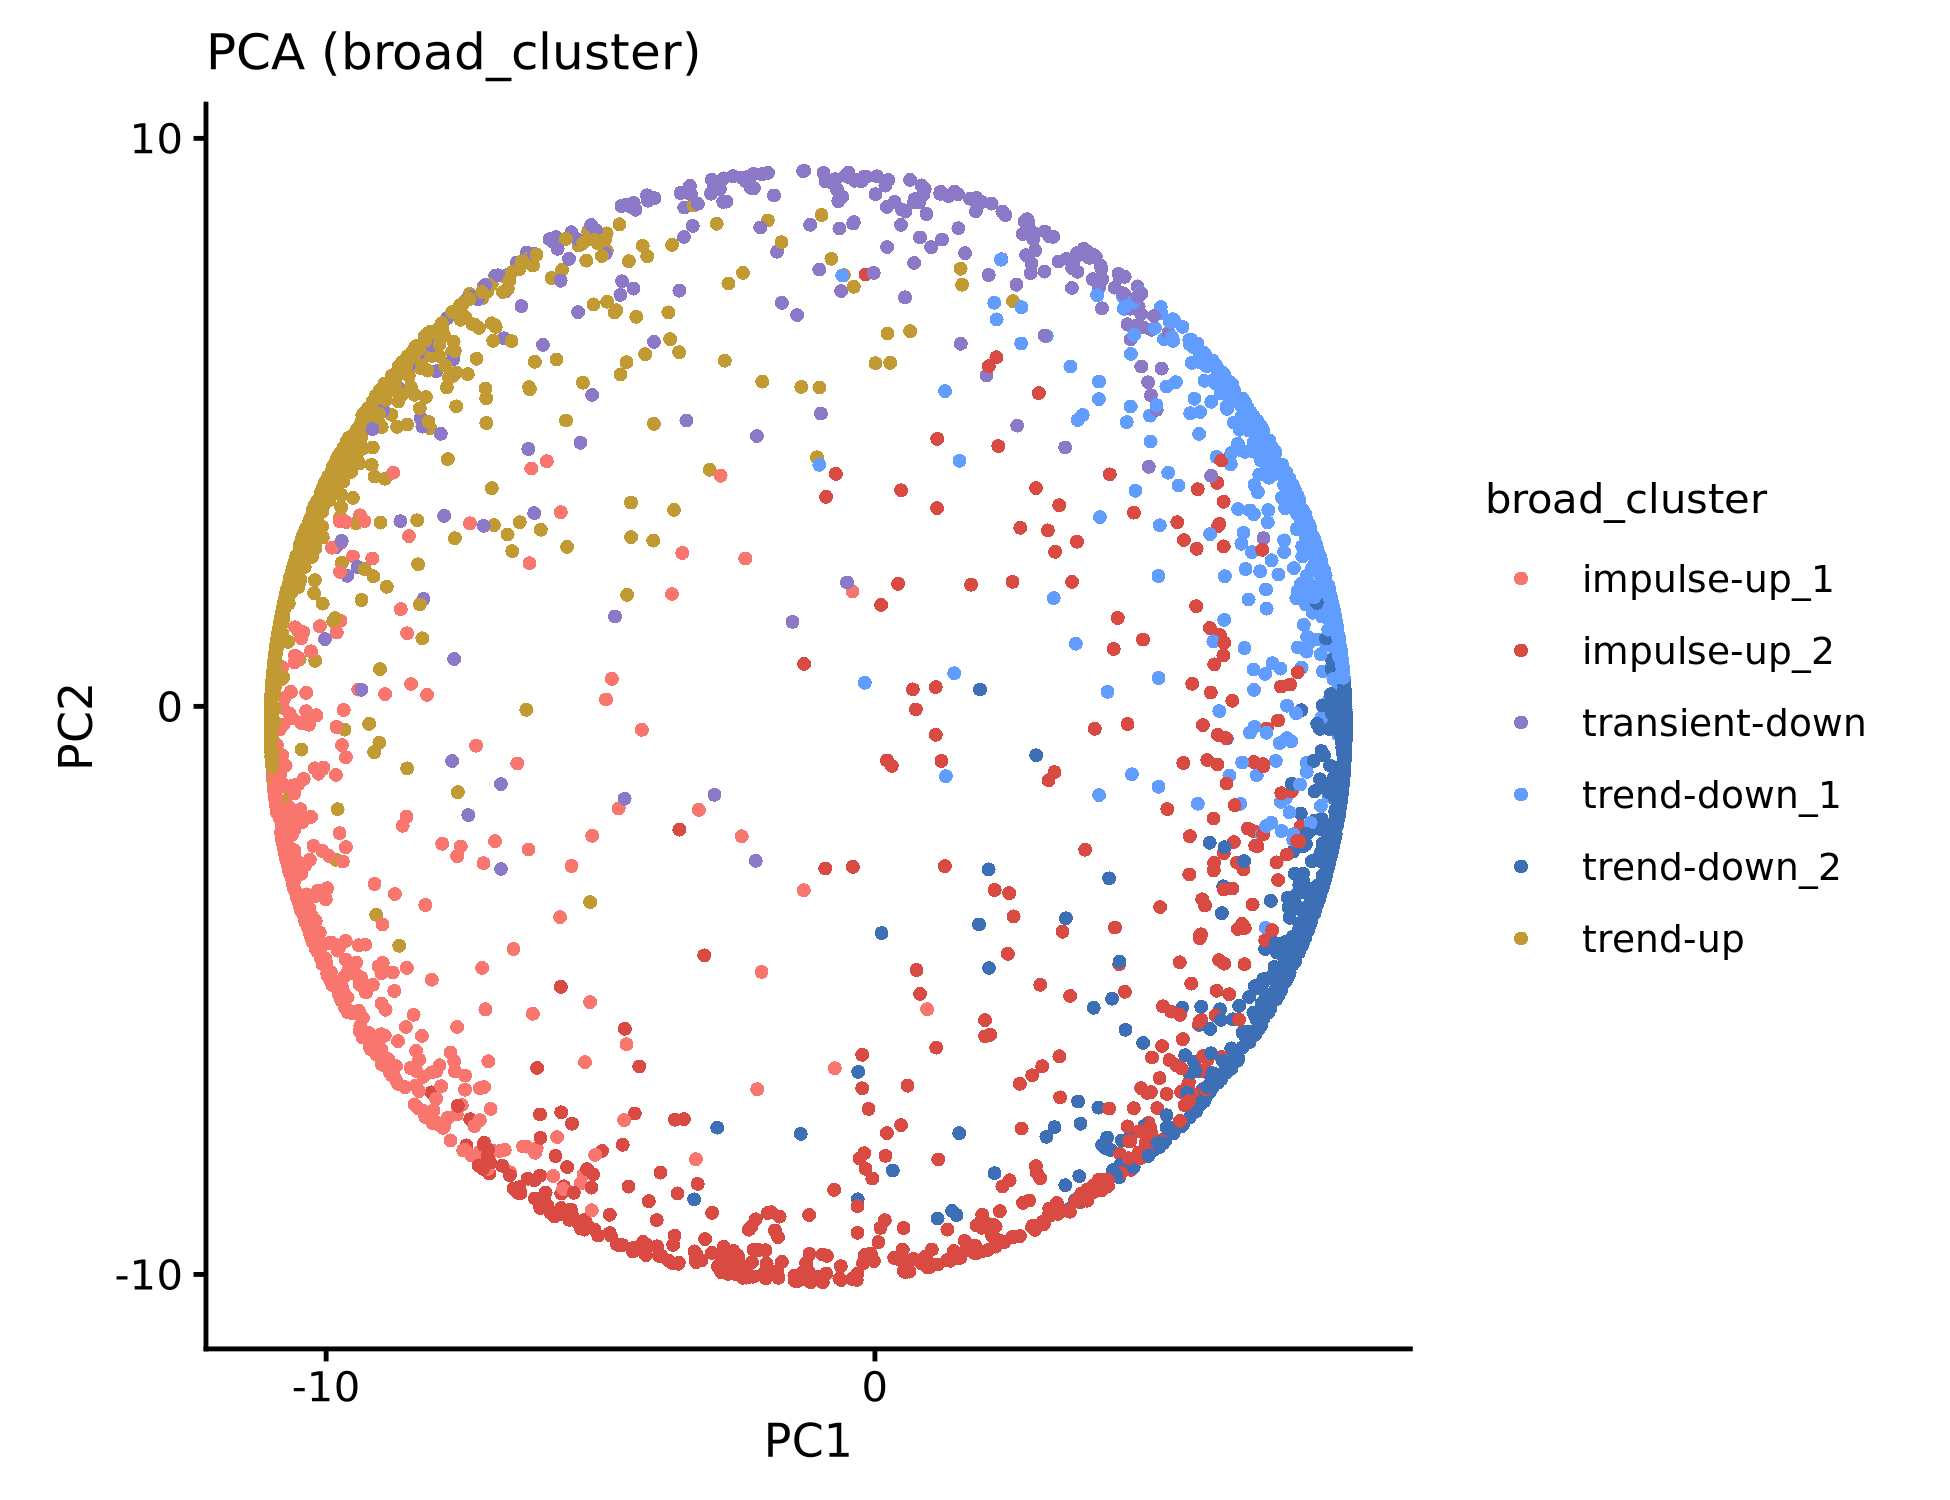

In [2]:
cp.pl.trajectory_features(
    adata,
    basis="X_pca",
    x="PC1",
    y="PC2",
    color="broad_cluster",
    output=PLOT_DIR / "trajectory_feature_space.svg",
)

## Broad dynamic modes

One row per broad mode: median and IQR of the z-scored trajectories (first panel), then the 10 trajectories with the highest Wald statistic. Shown for strongly responding K562 + TNF-alpha trajectories (|peak log2FC| > 0.5).

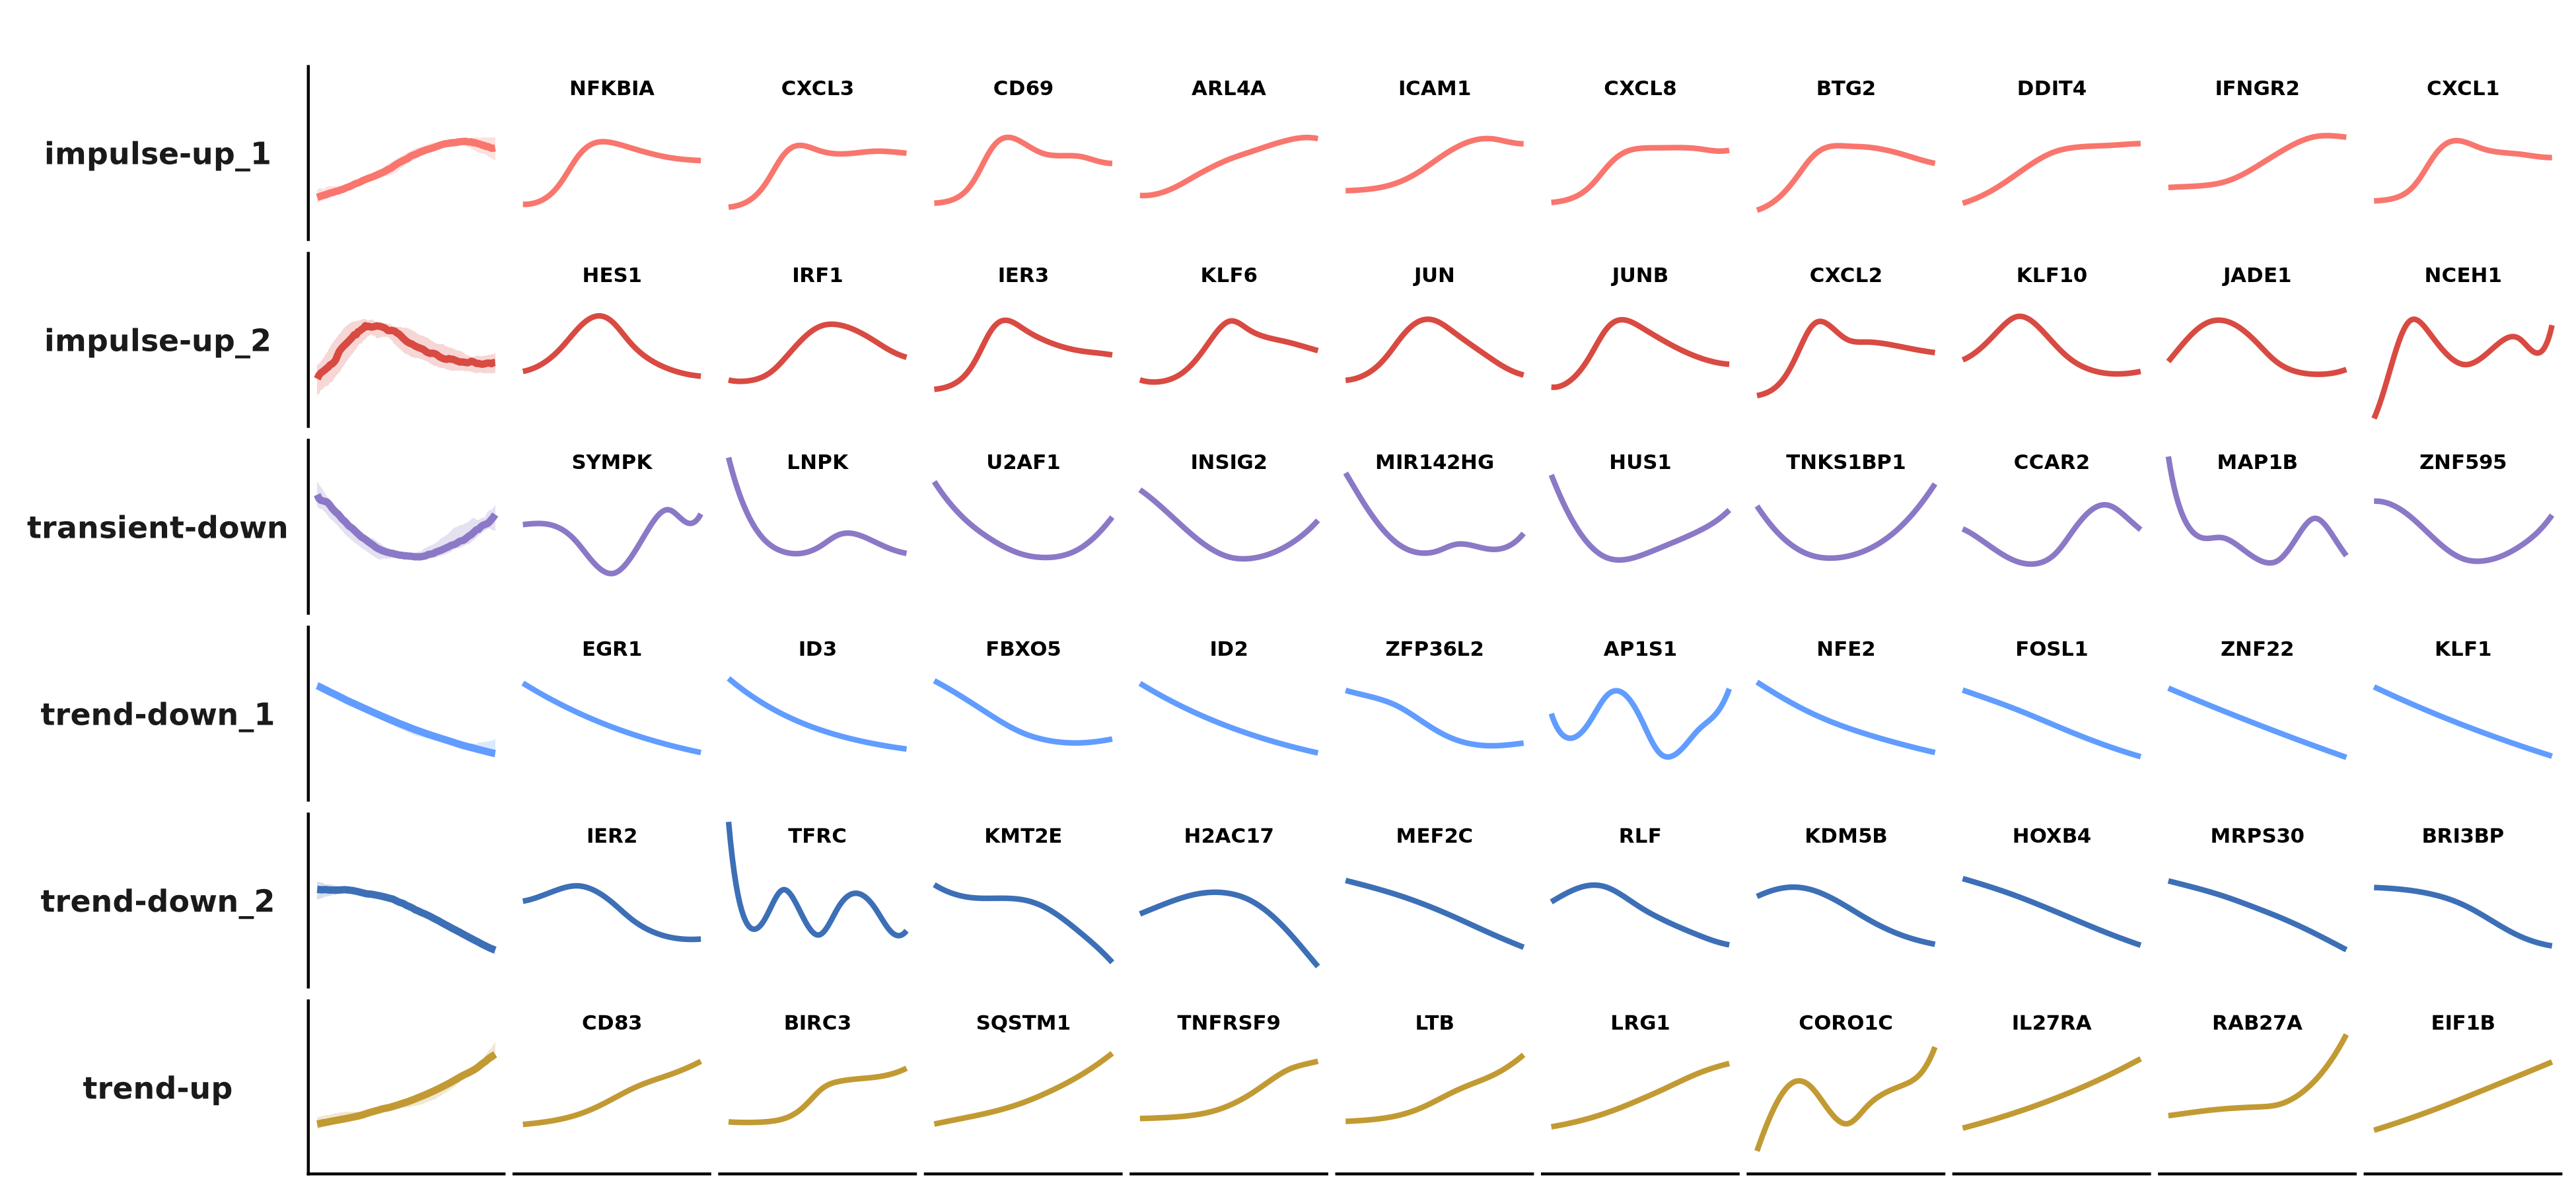

In [3]:
k562a = adata[
    (adata.obs["cell_type"] == "K562a") & (adata.obs["peak_log2fc"].abs() > 0.5) & (adata.obs["pvalue_1"] < 0.05)
]
cp.pl.cluster_medoids_and_top_genes(
    k562a,
    "broad_cluster",
    seed=10,
    top_n=10,
    gene_title_mode="gene_sym",
    use_silhouette_alpha=False,
    show_sil_text=False,
    show_median_iqr=True,
    show_gene_titles=True,
    title="",
    output=PLOT_DIR / "broad_cluster_medoids.svg",
    width=13,
    height=6,
)

## Fine clusters within broad modes

The fine clusters of each broad mode (all contexts), drawn the same way with the 5 top trajectories per fine cluster.

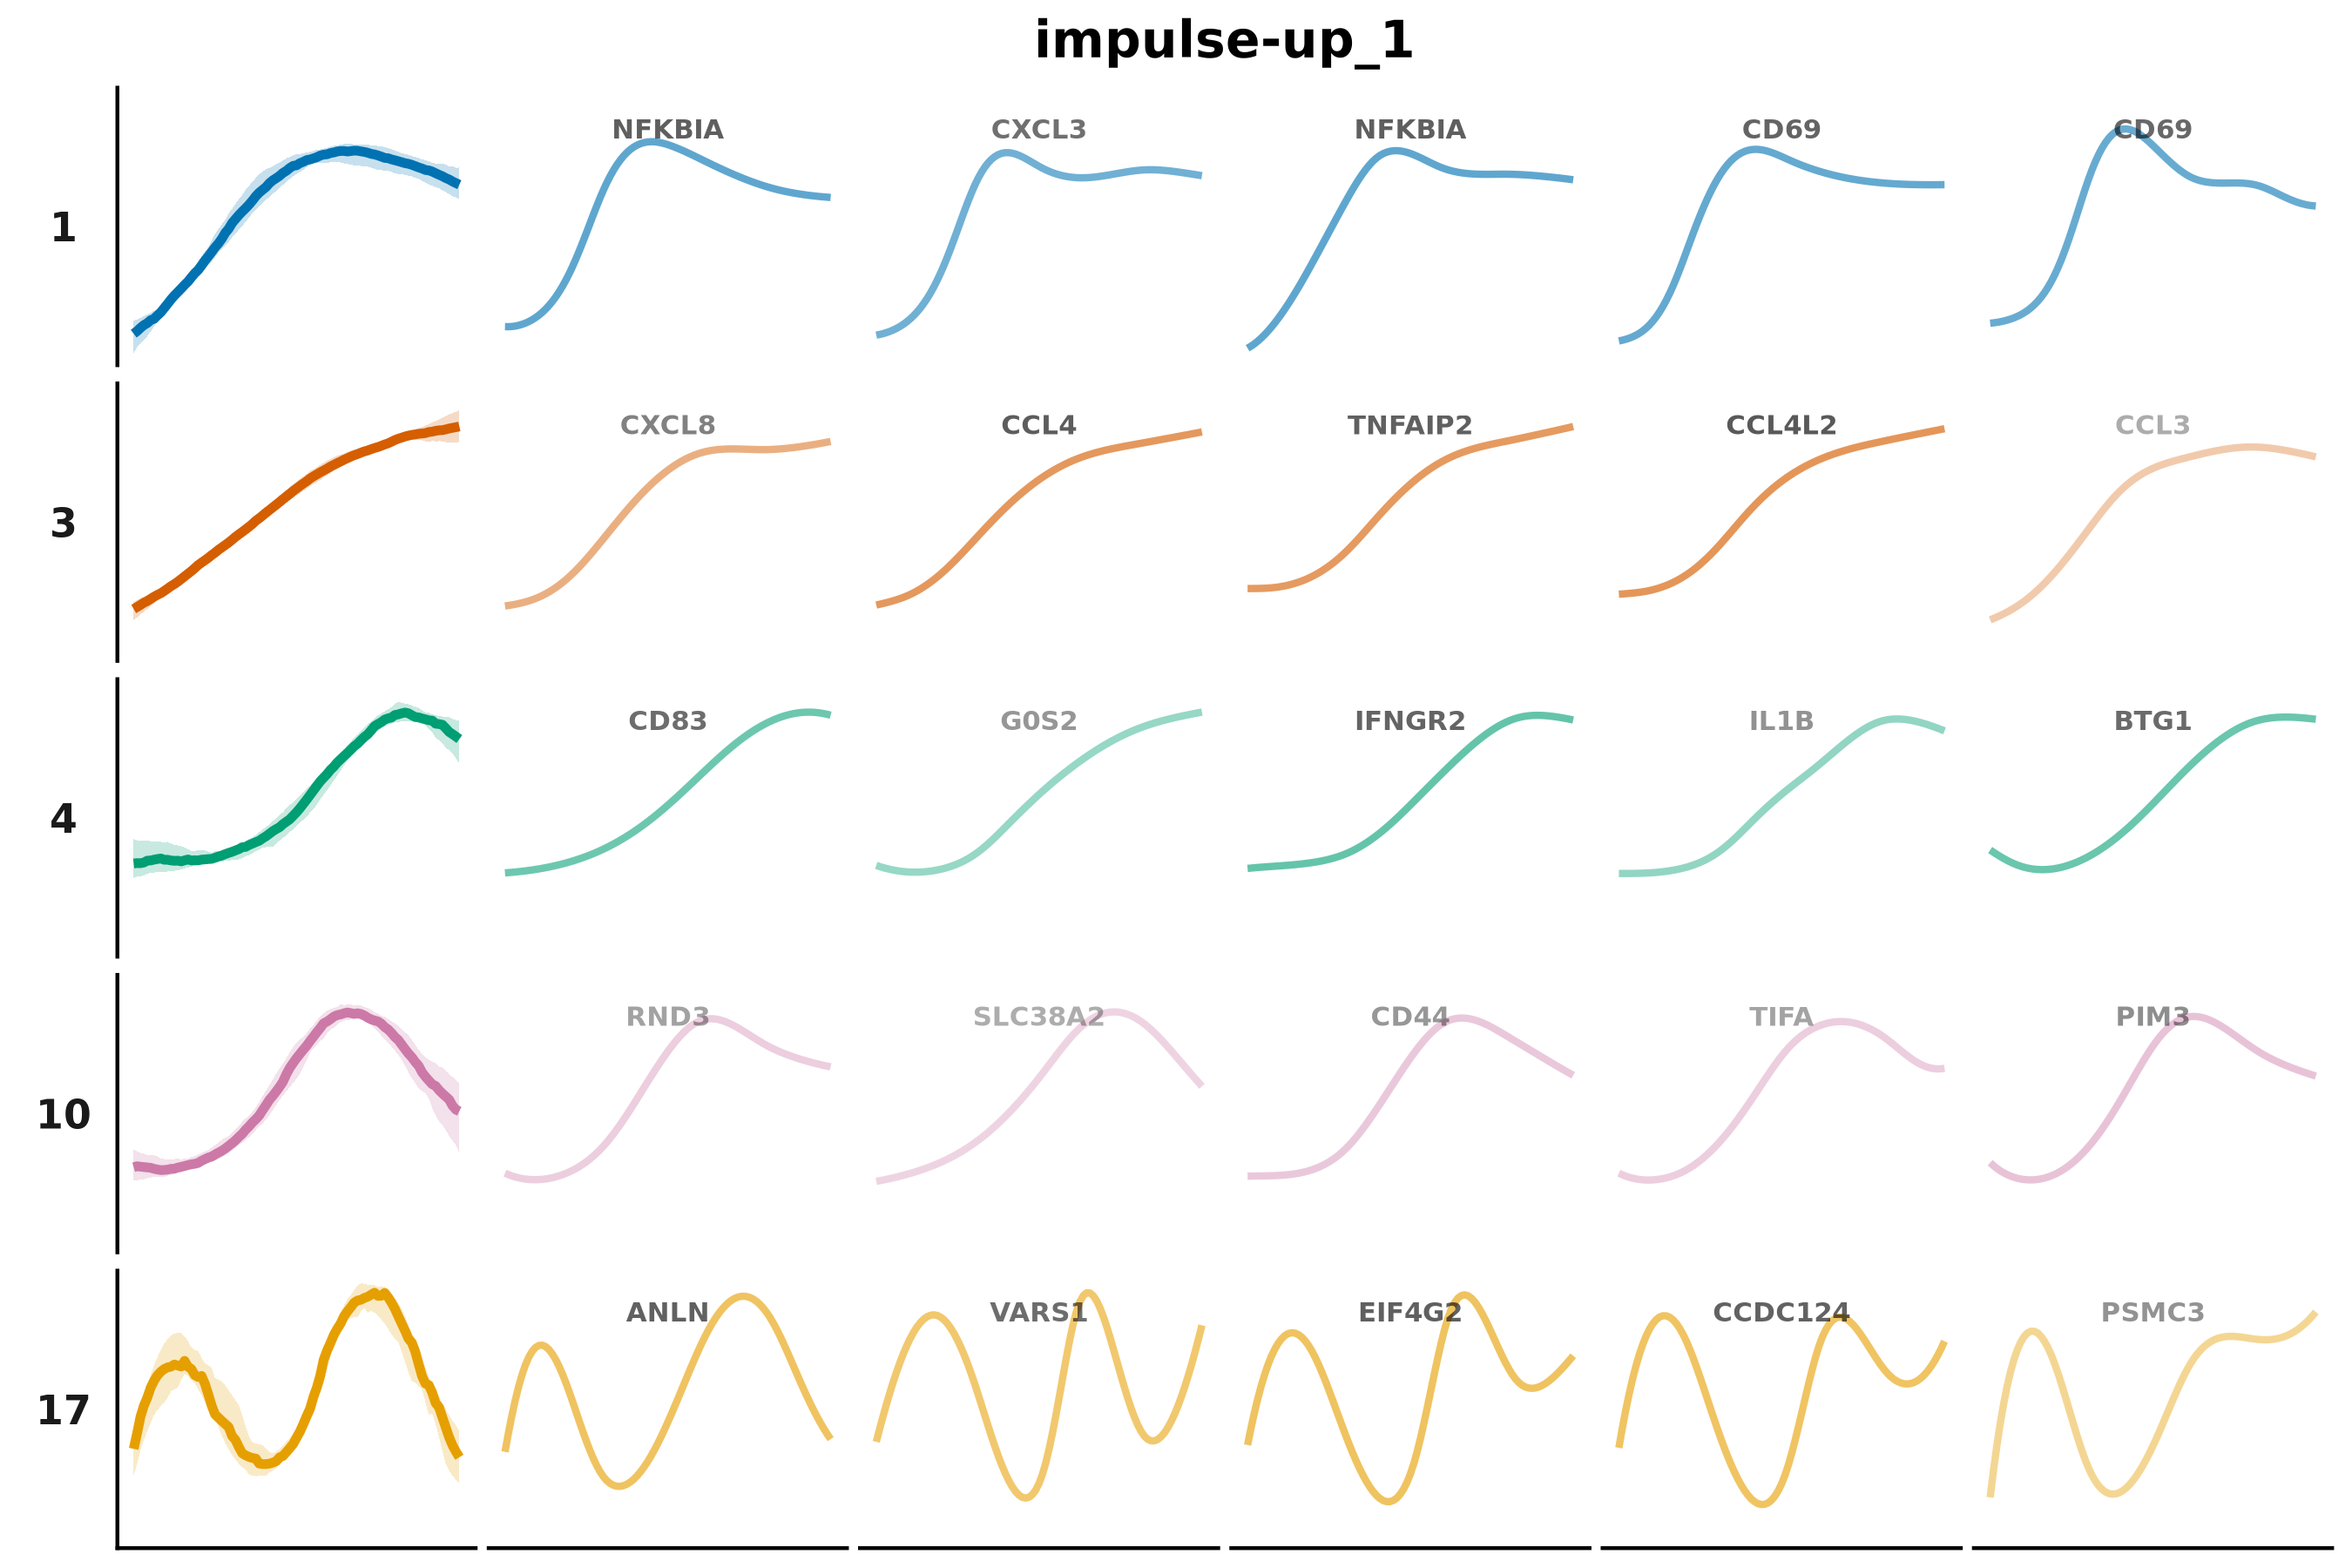

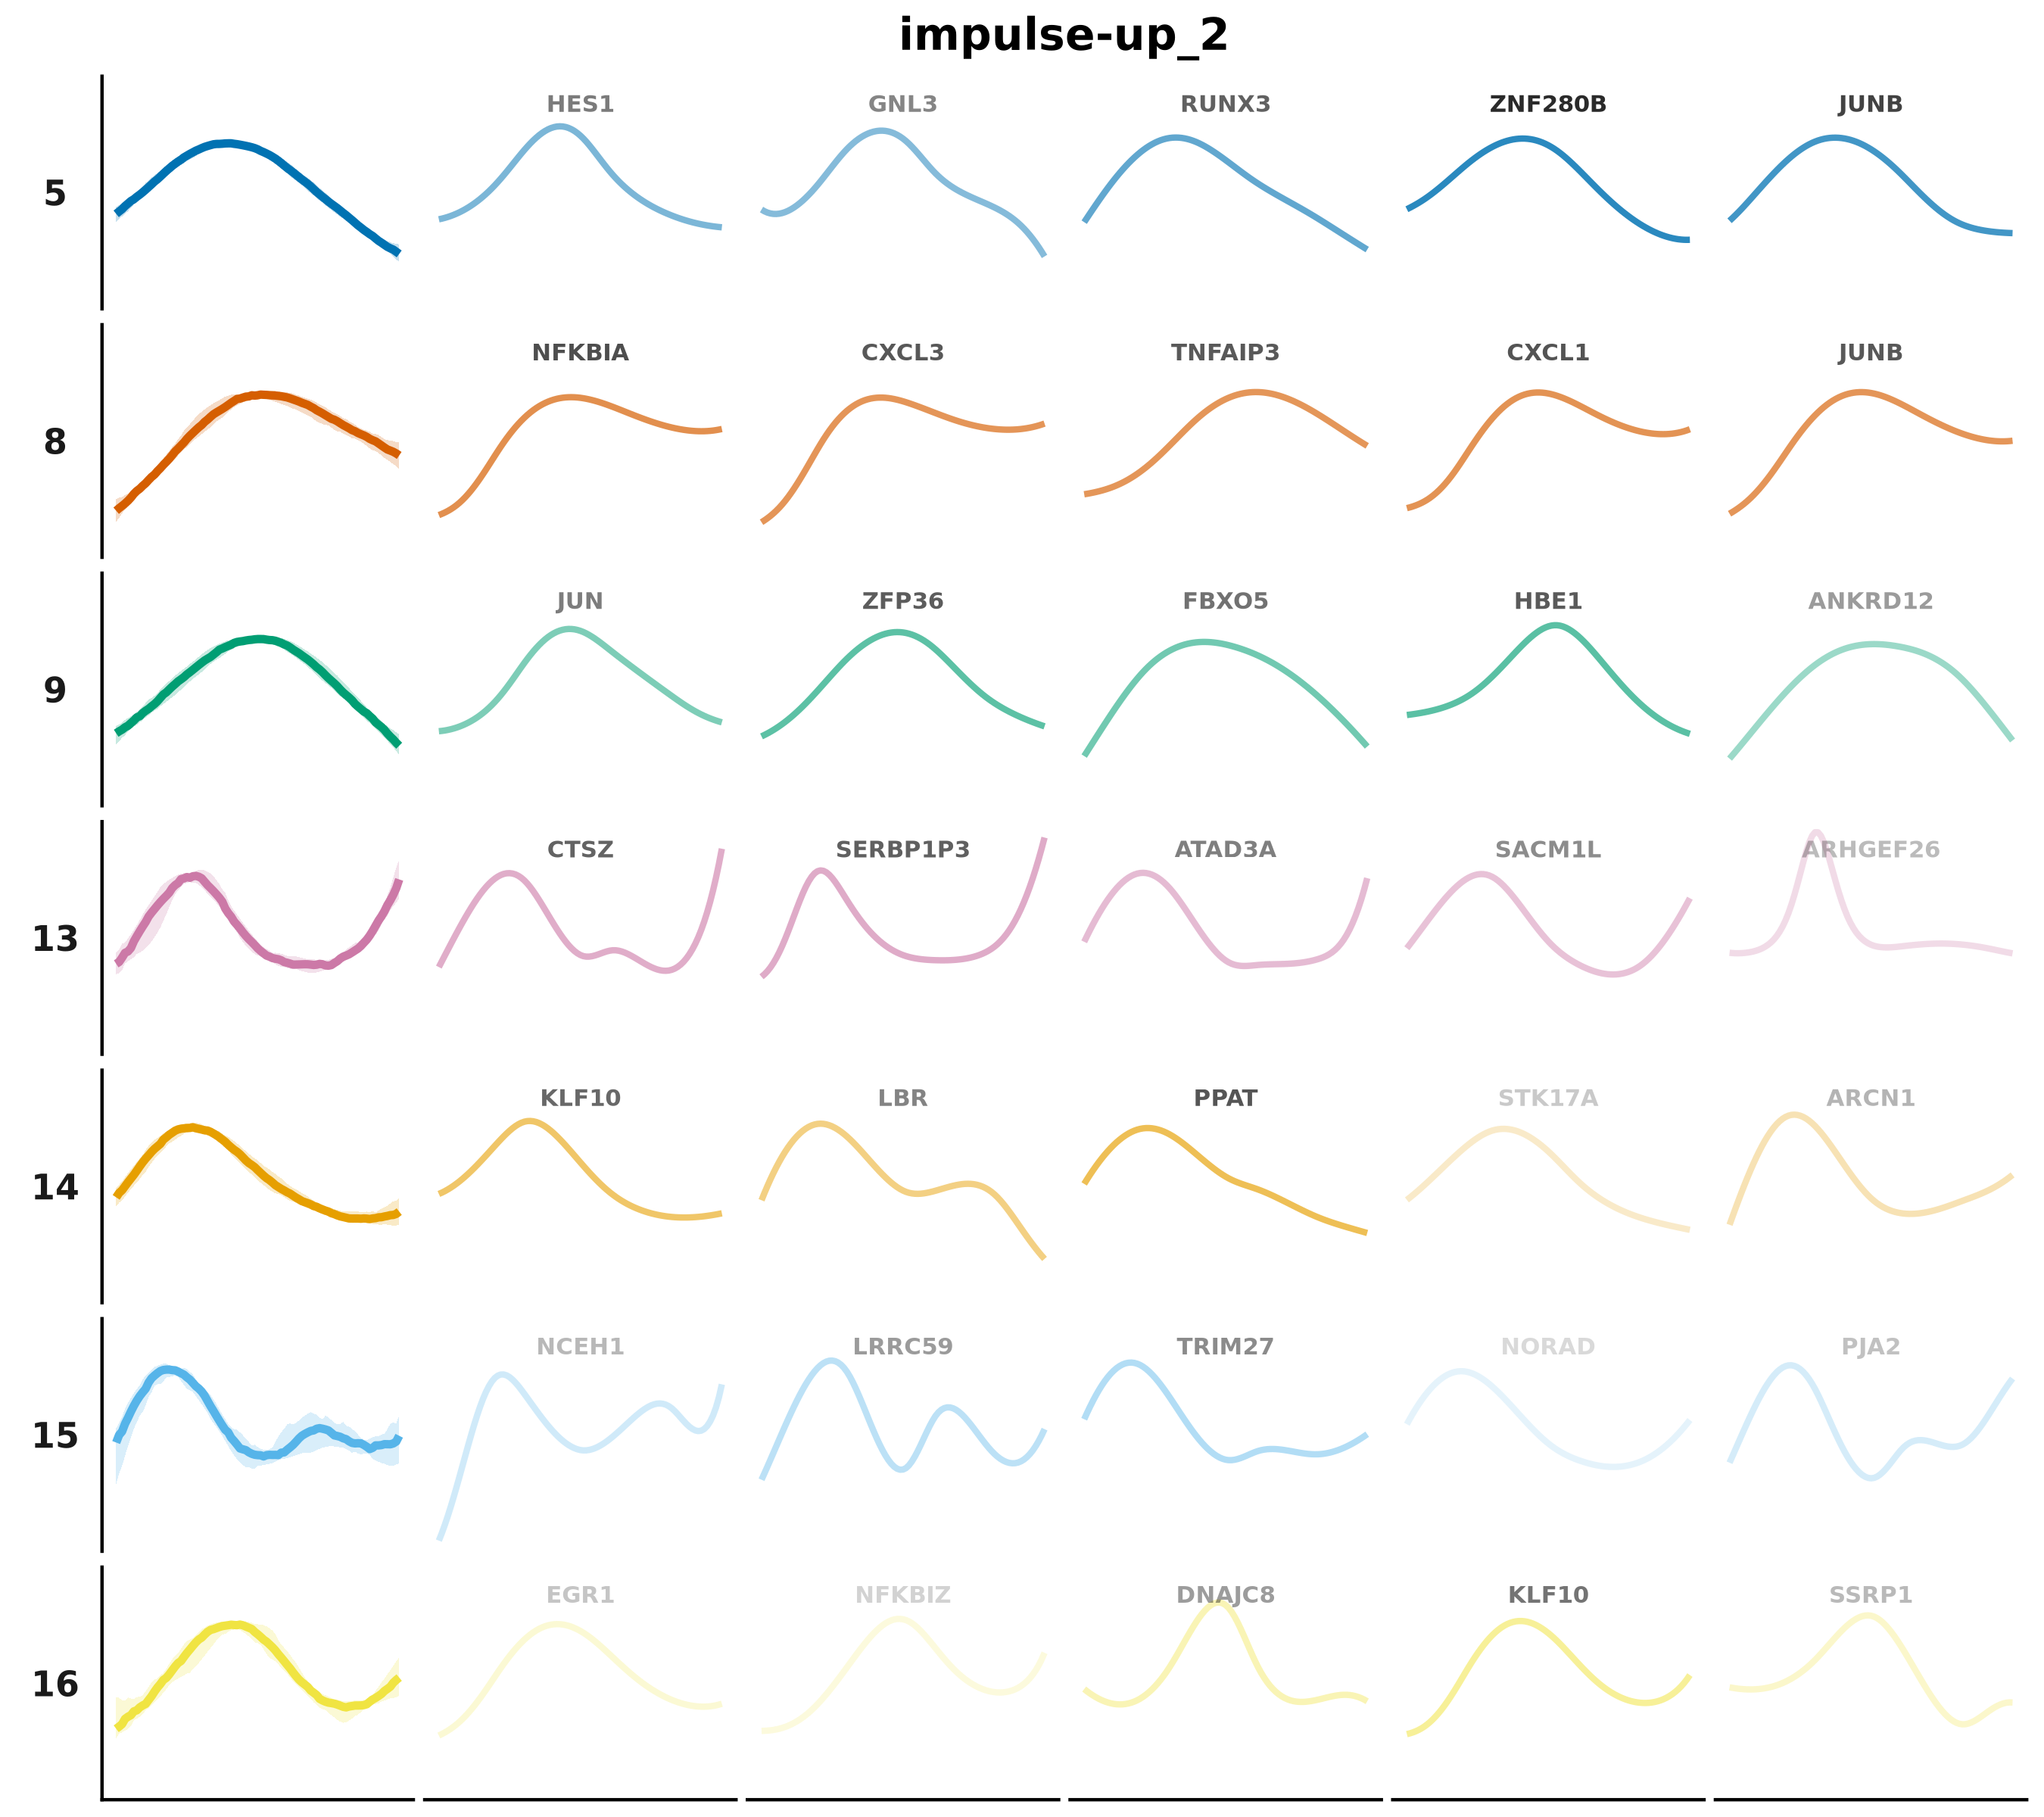

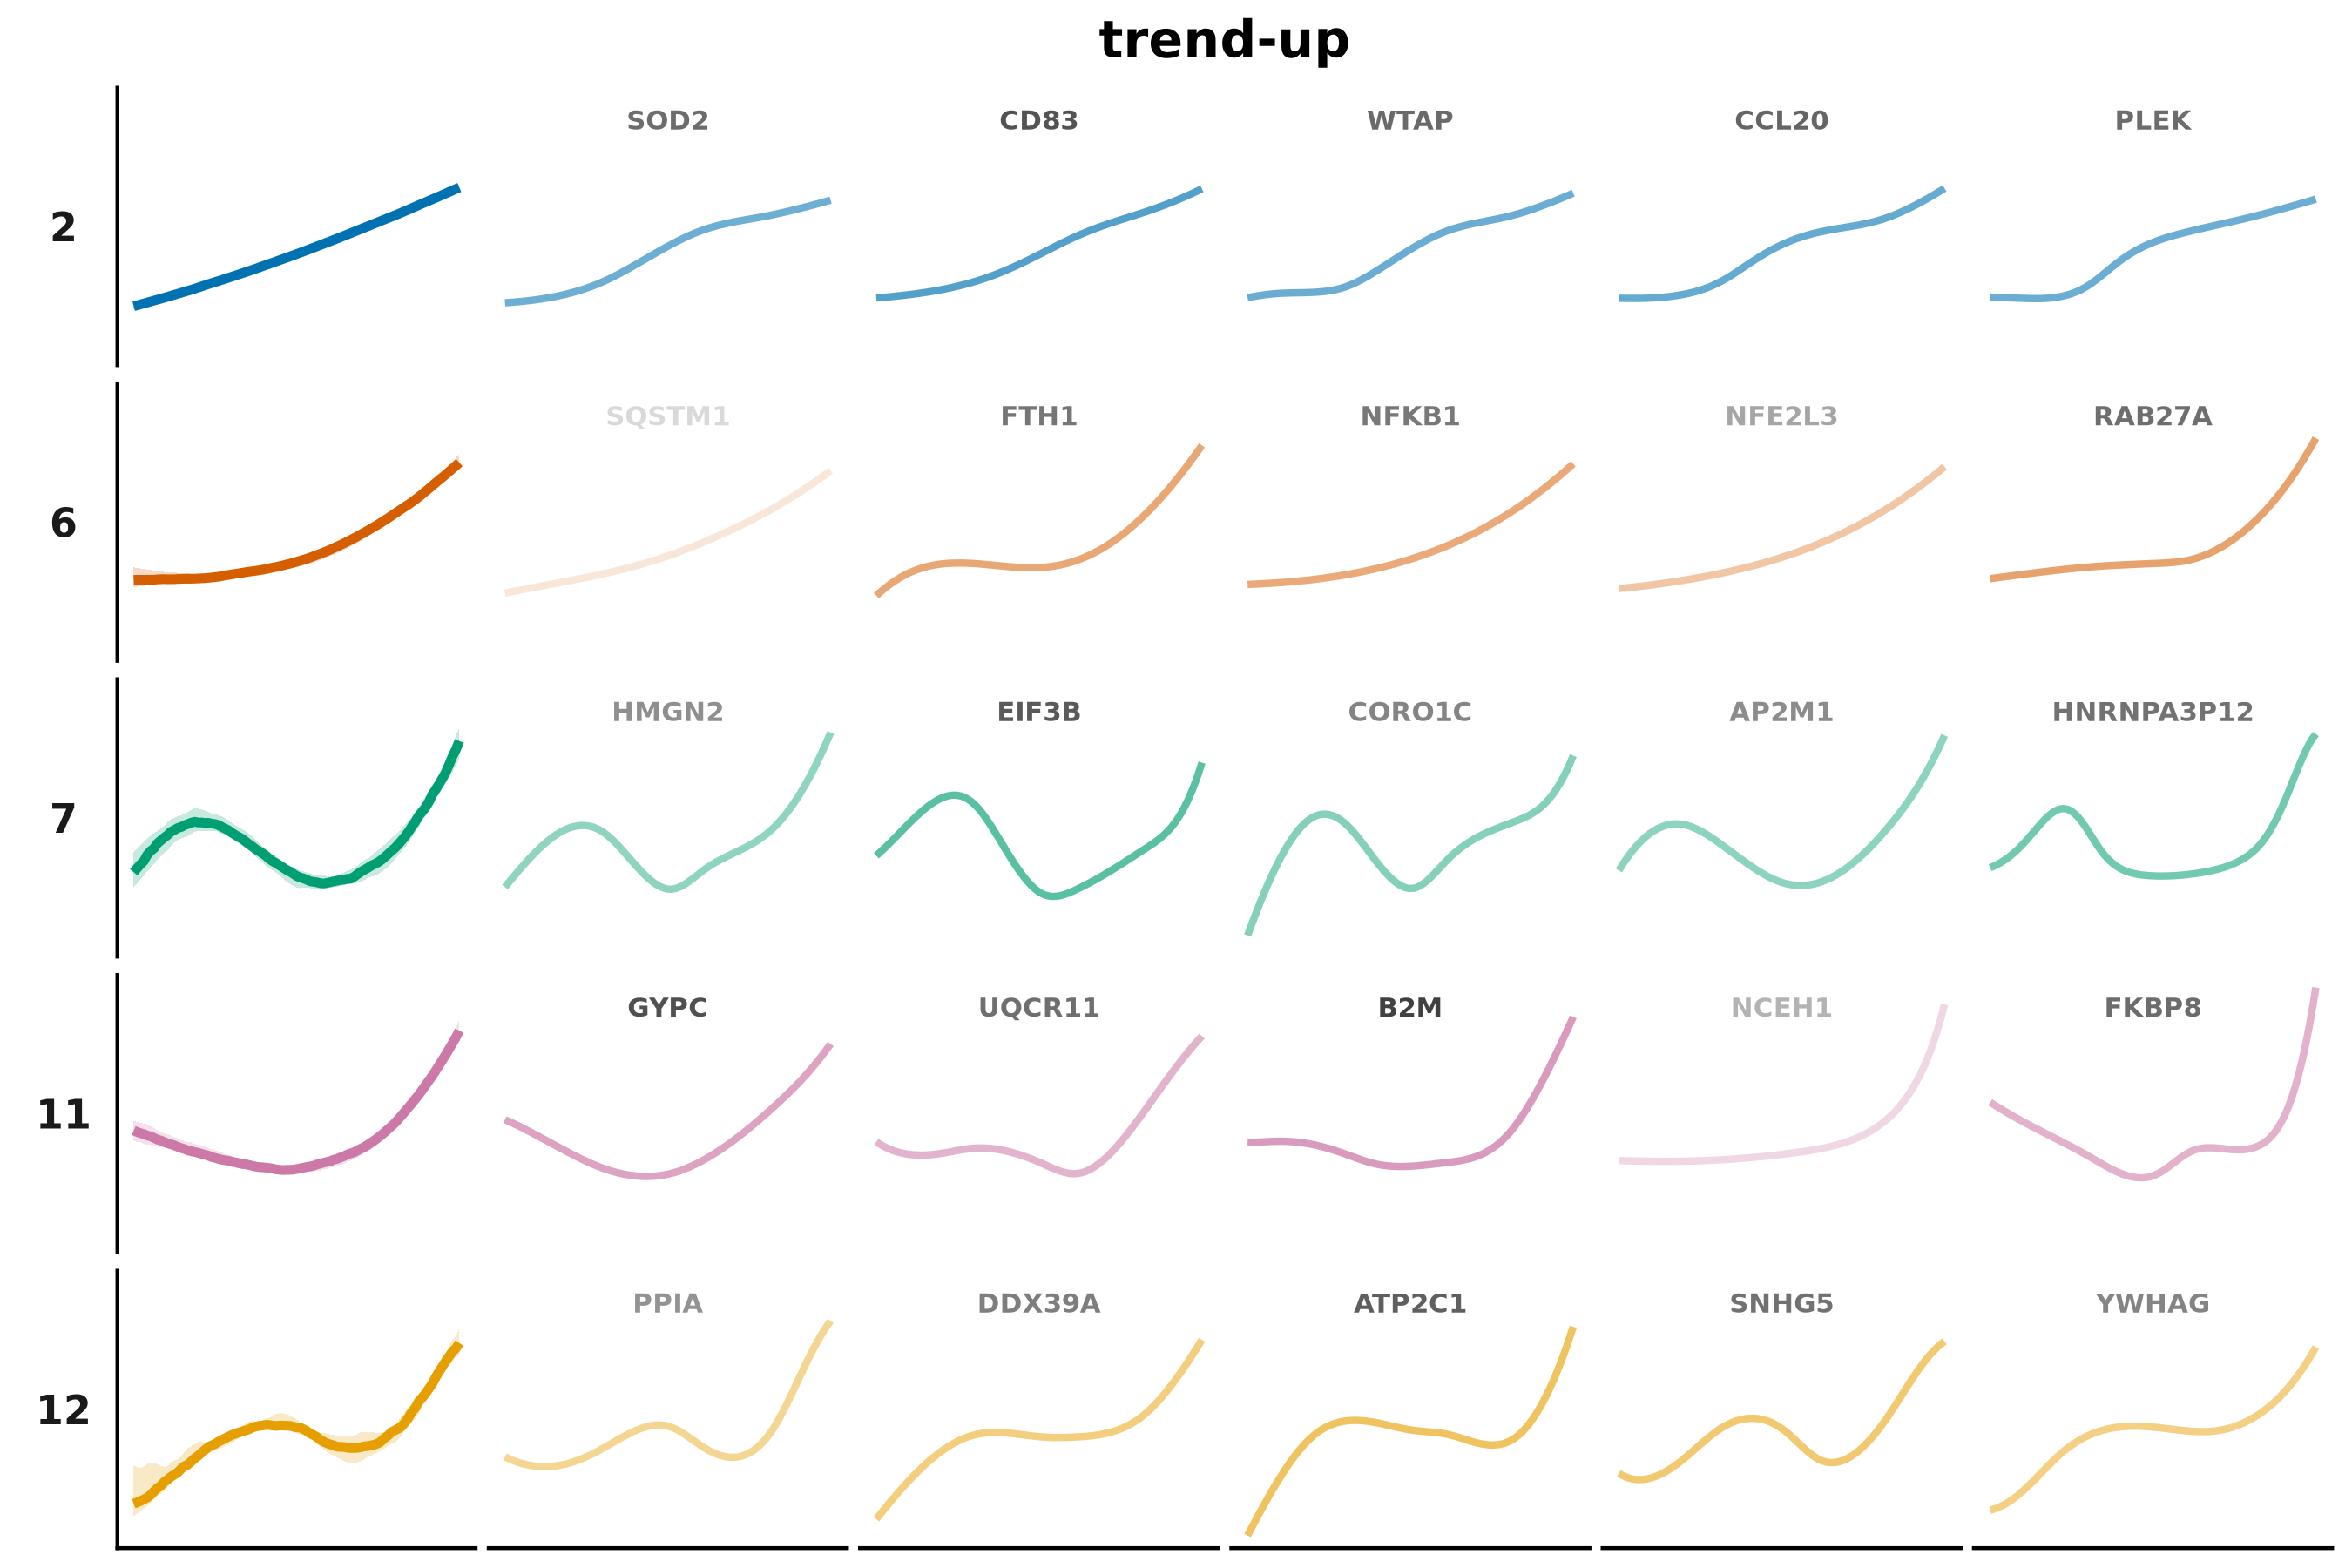

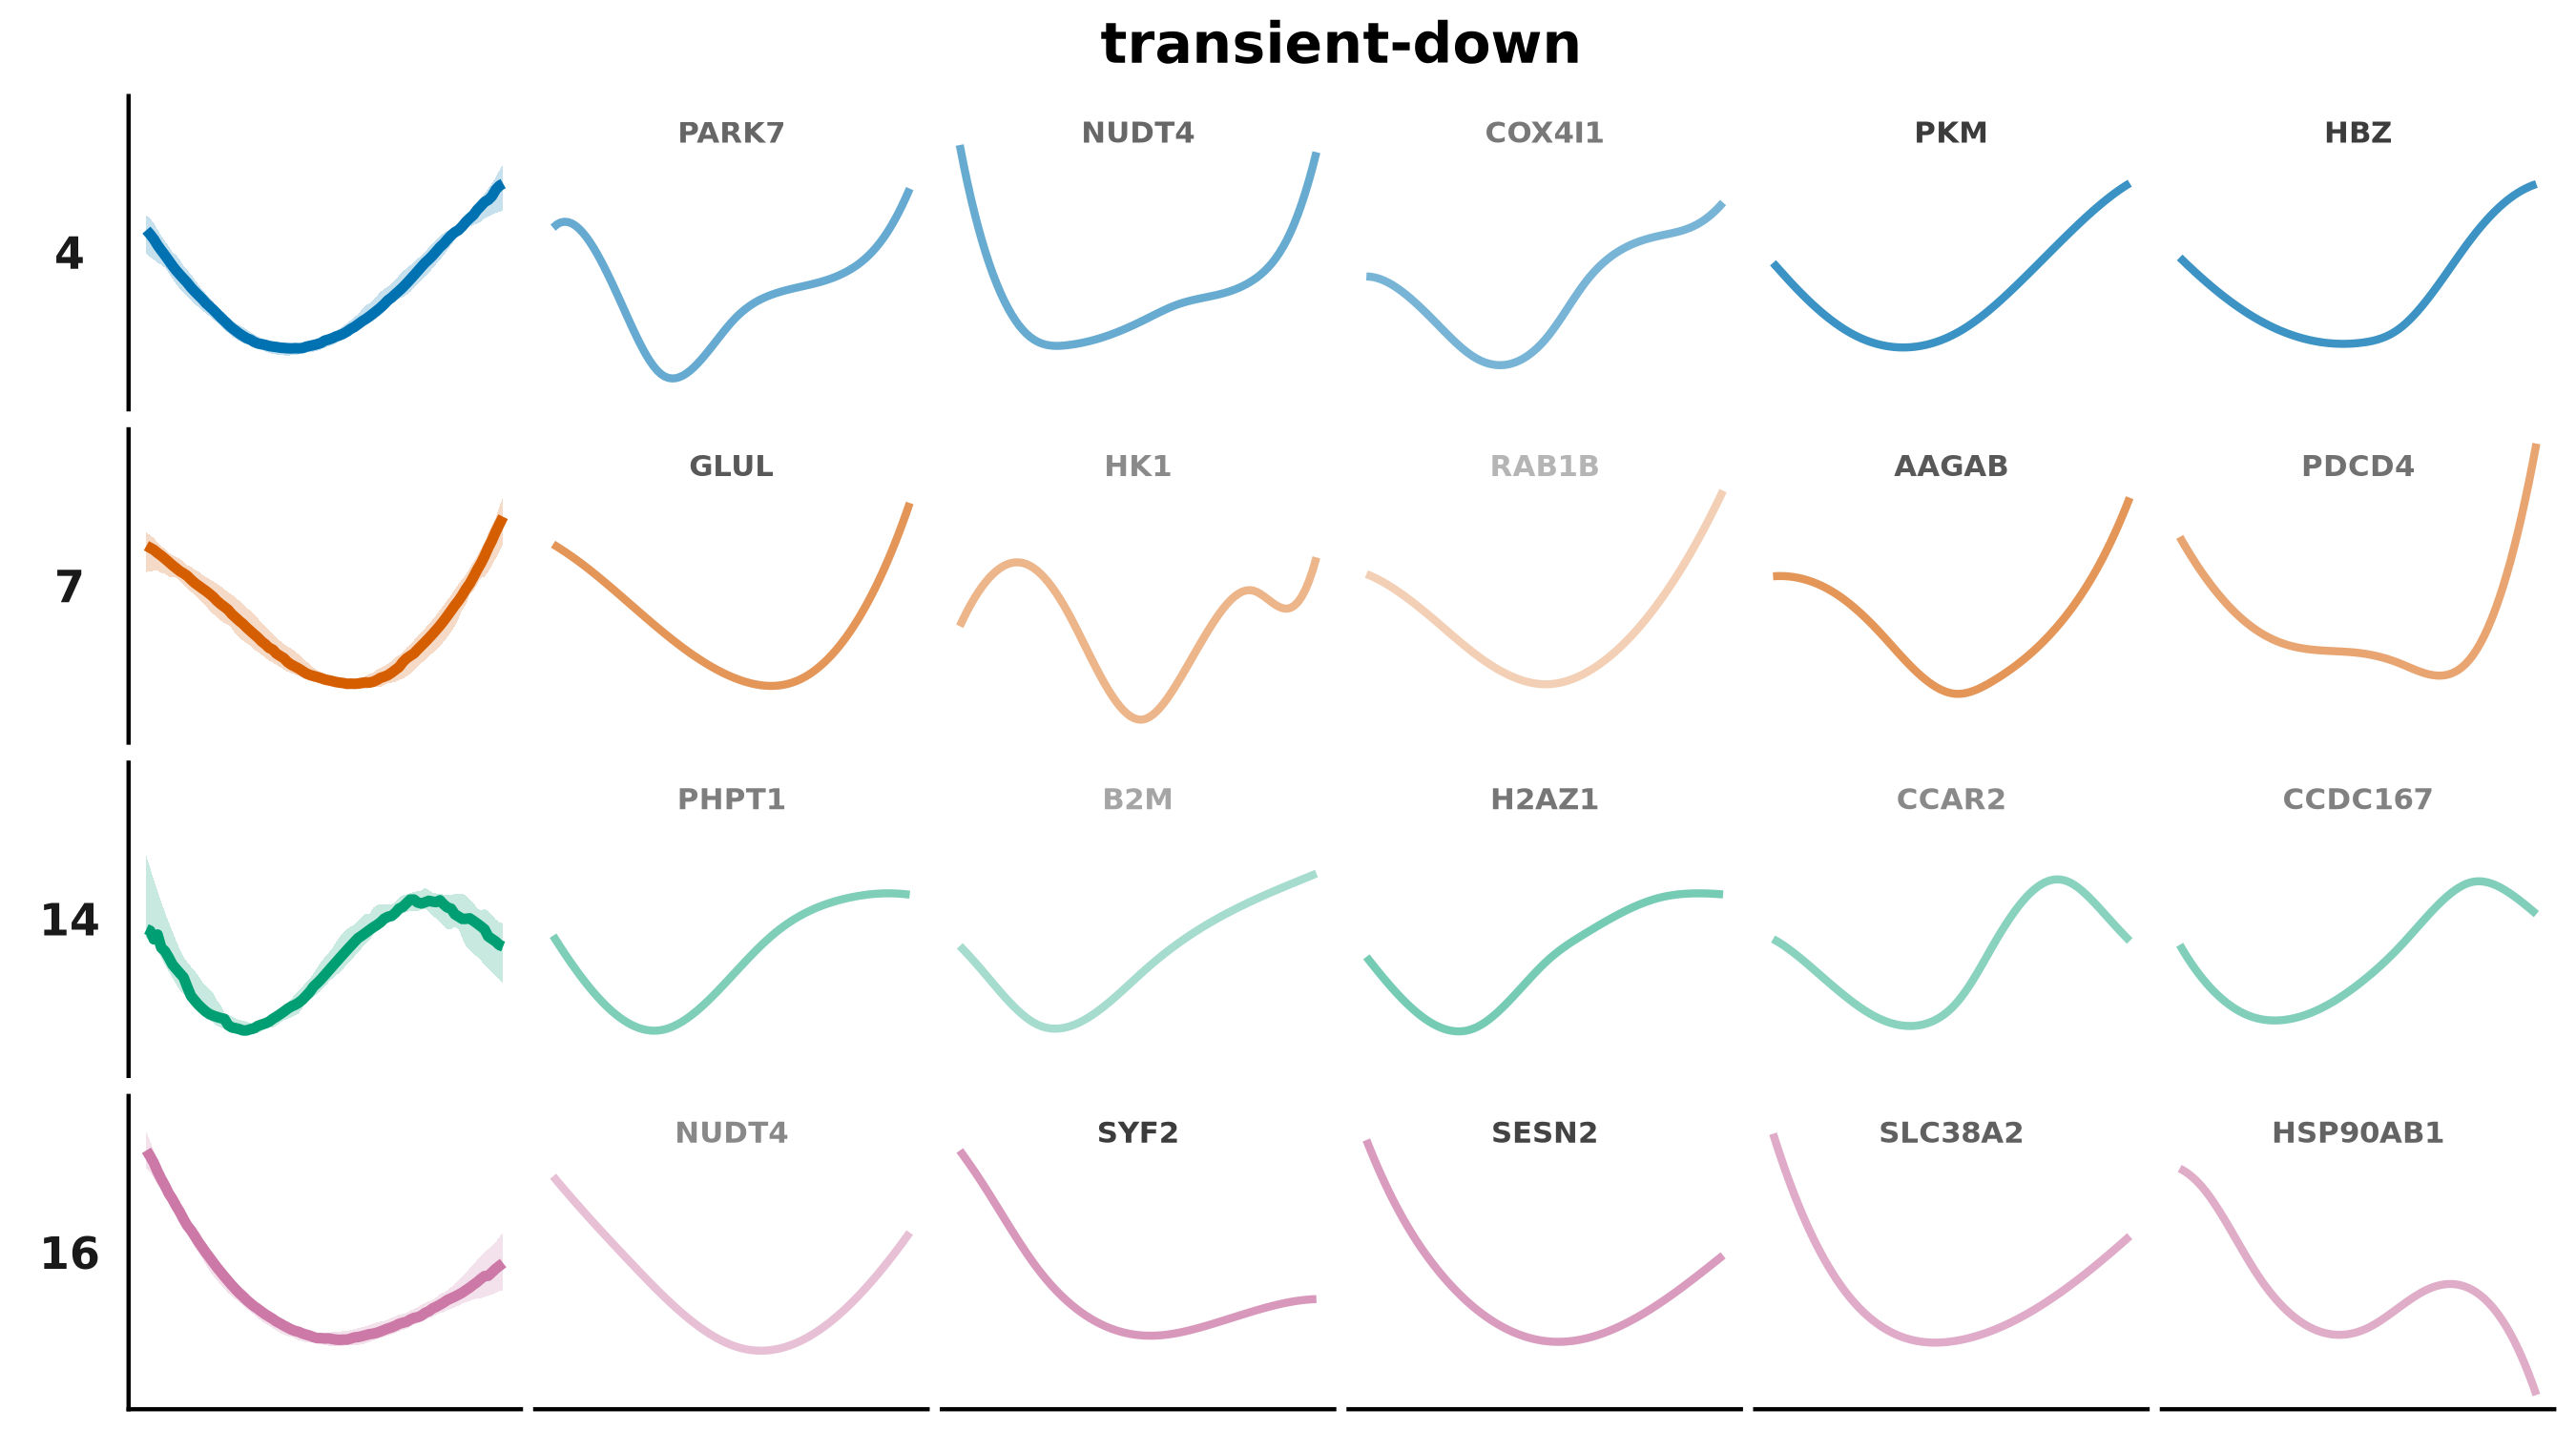

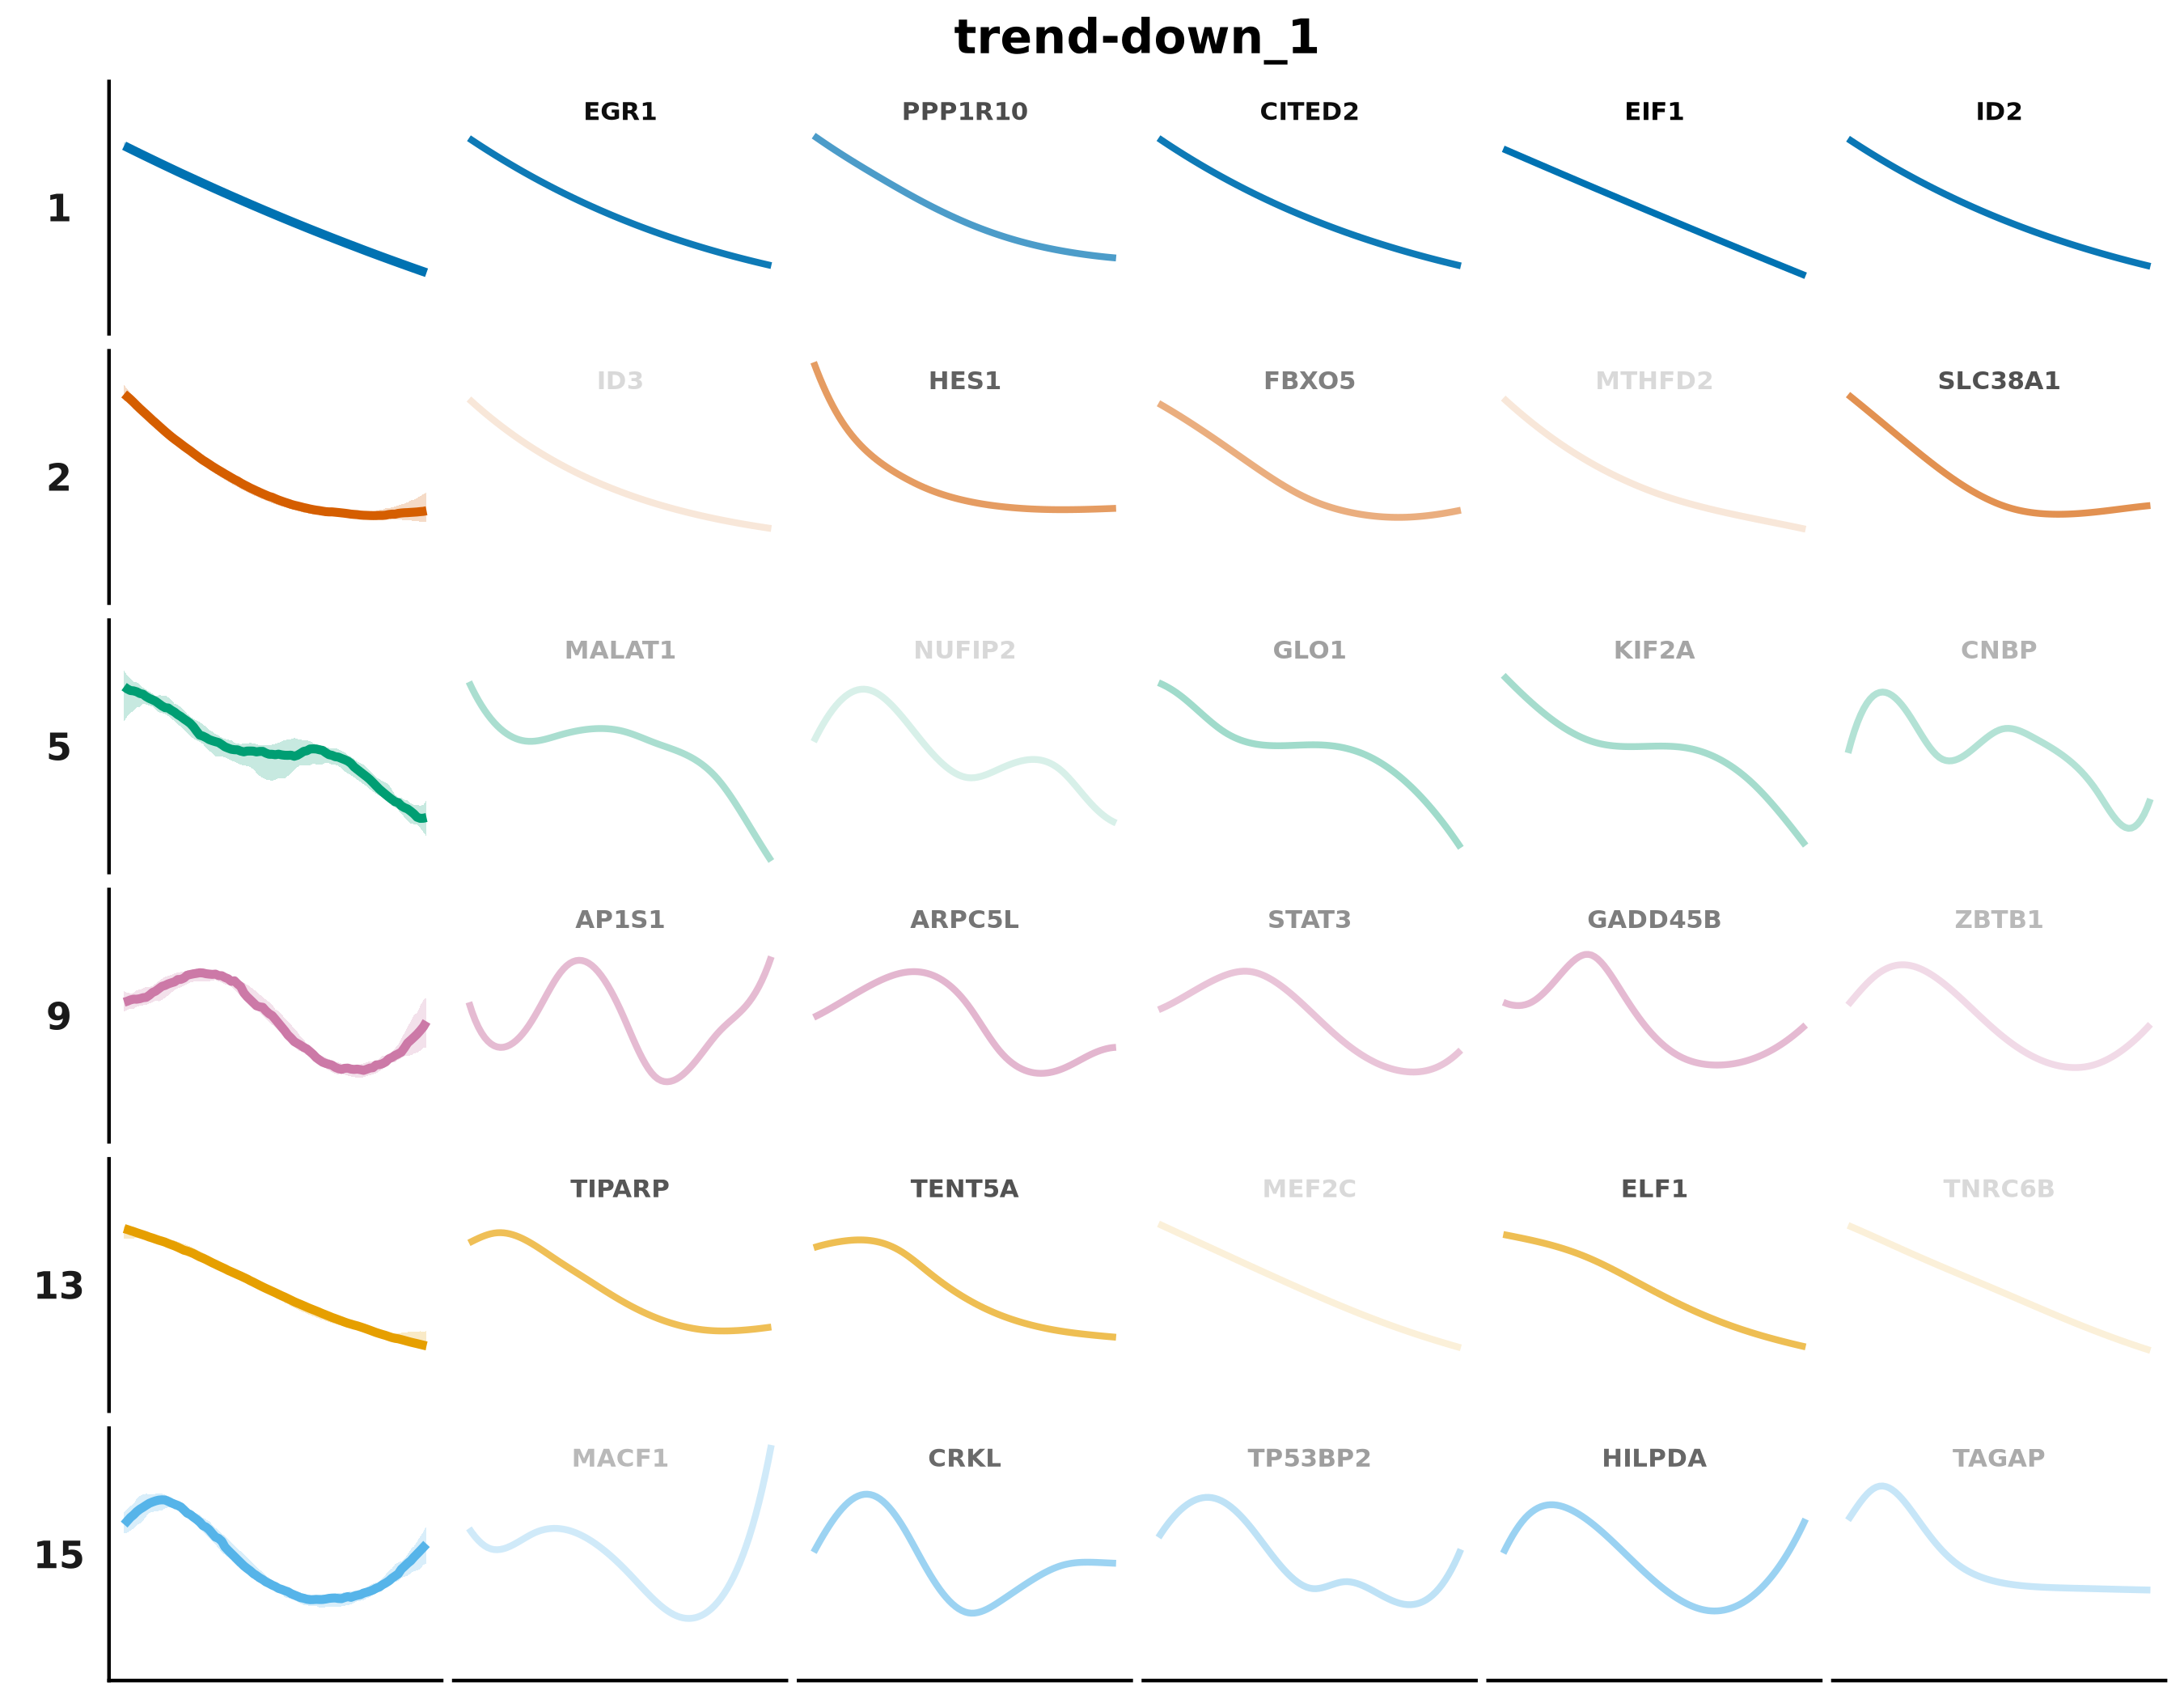

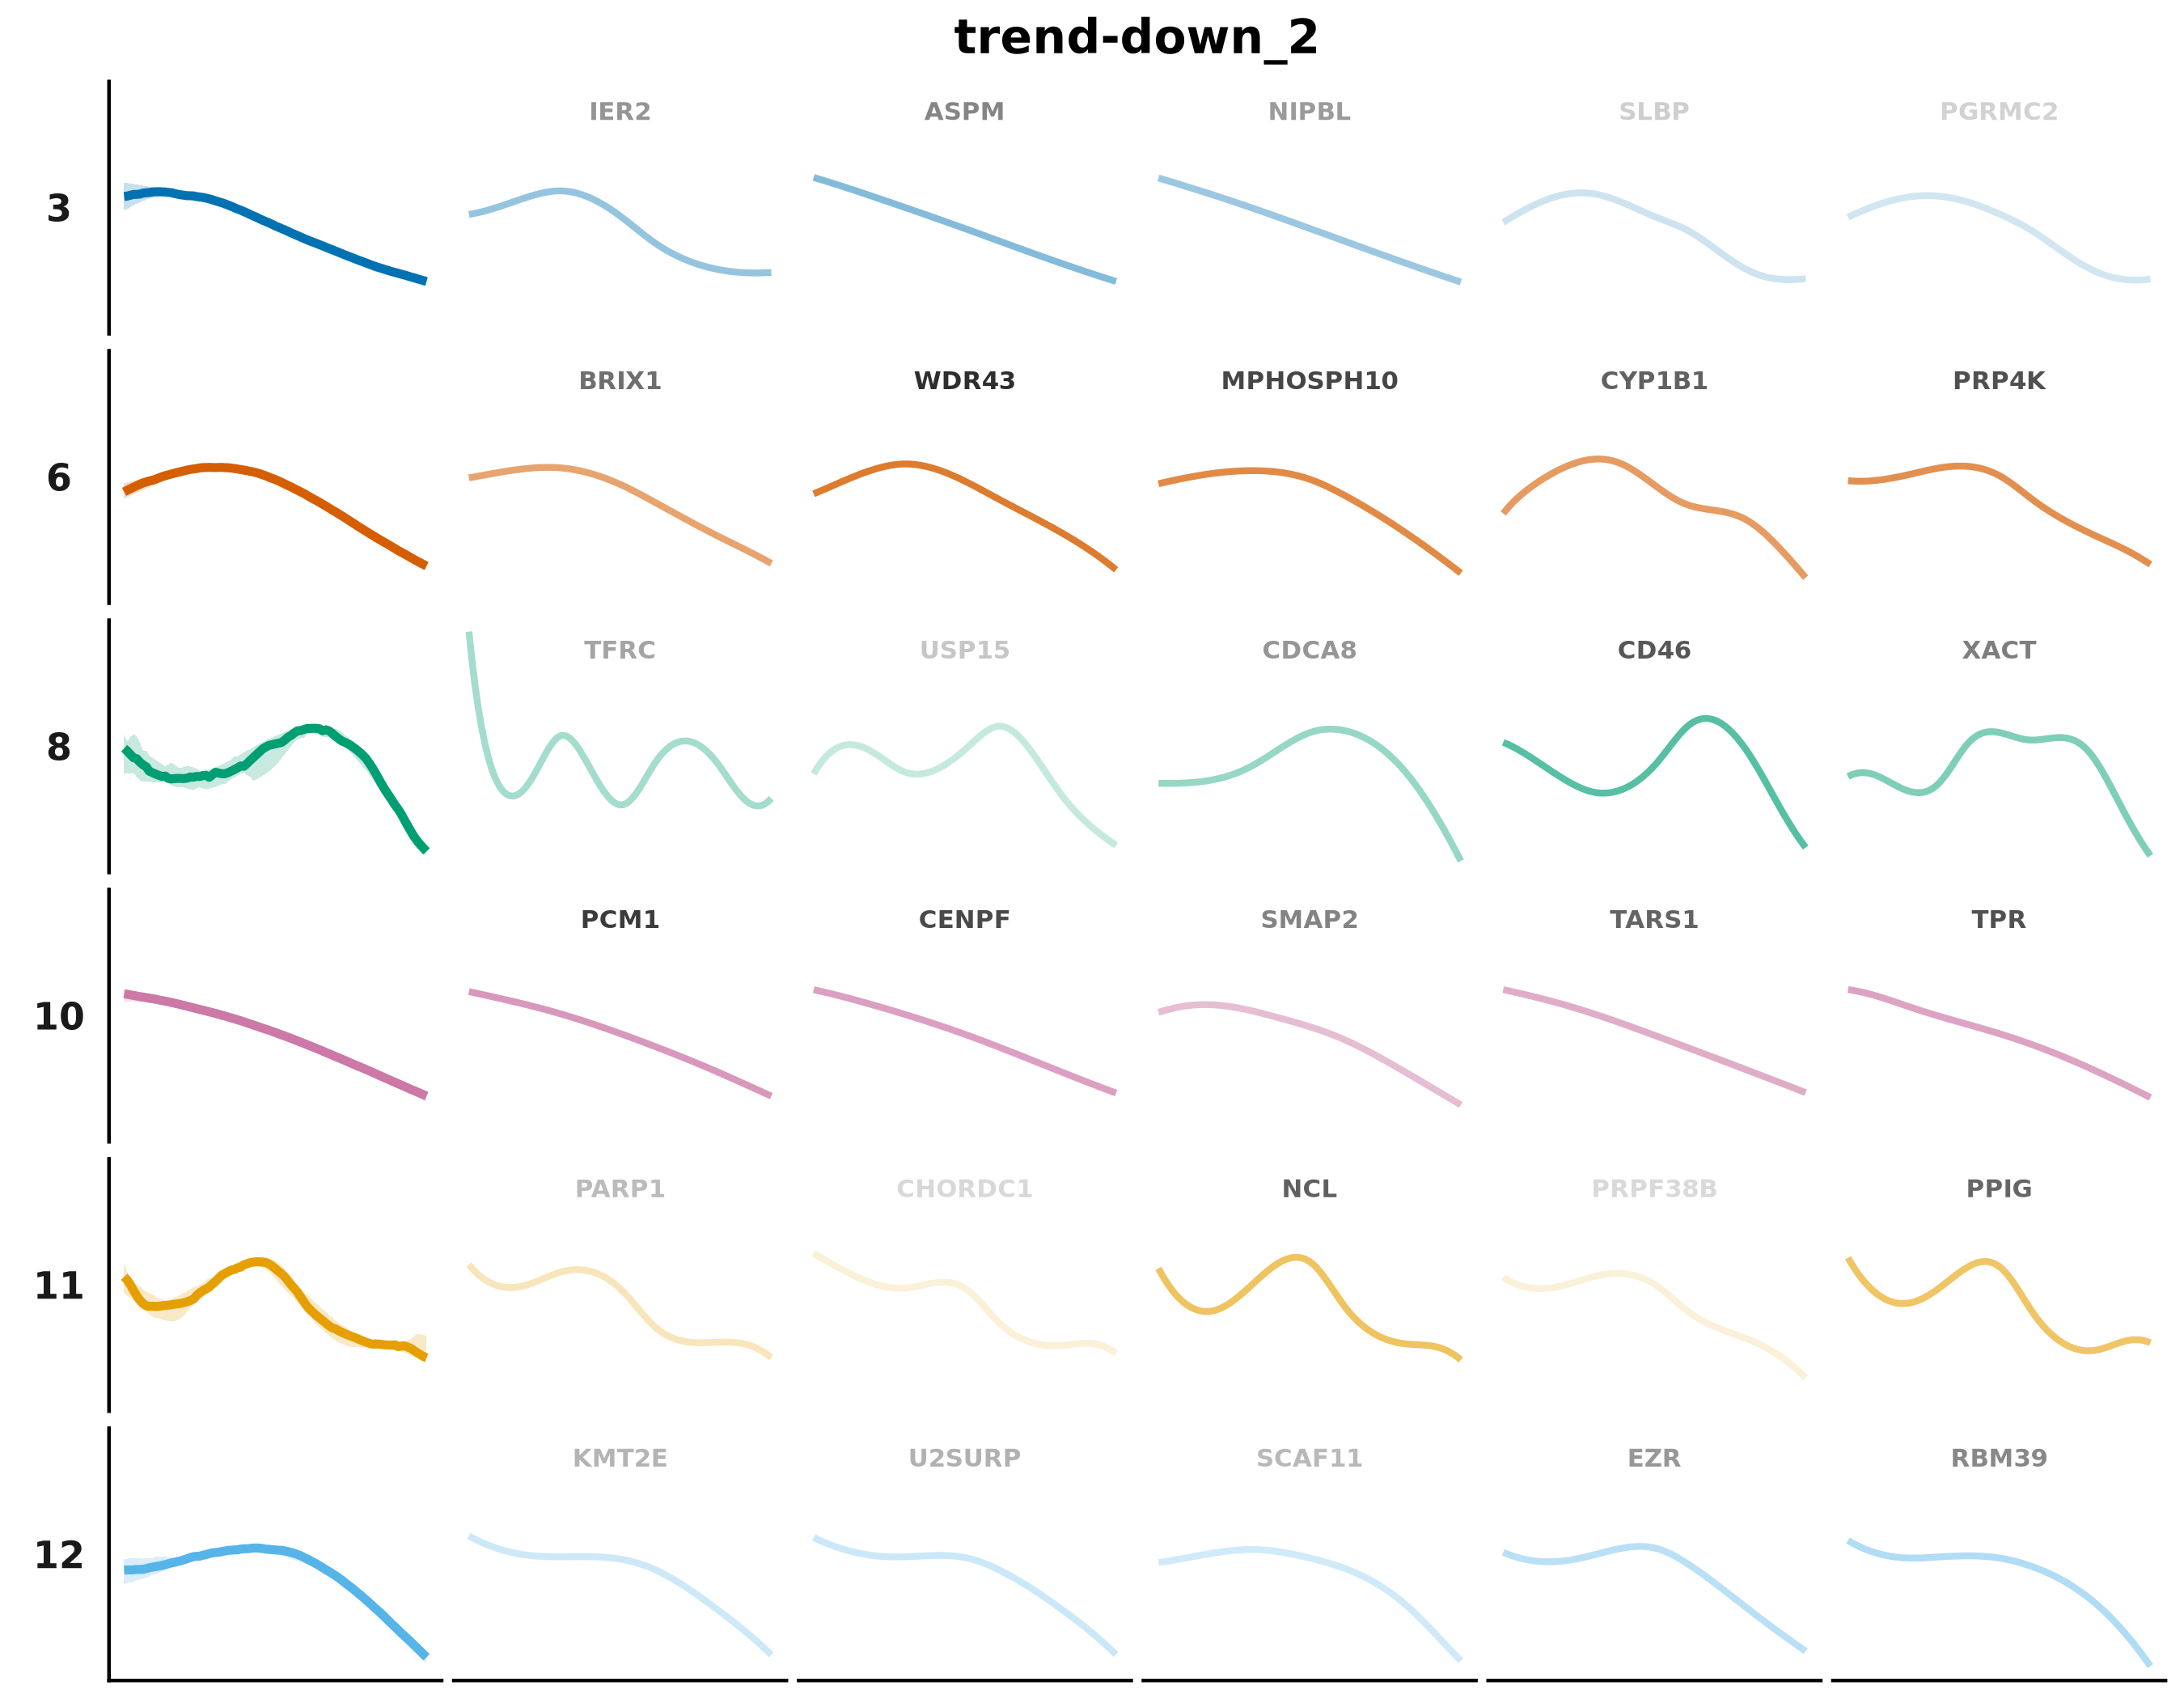

In [4]:
broad_order = ["impulse-up_1", "impulse-up_2", "trend-up", "transient-down", "trend-down_1", "trend-down_2"]

for mode in broad_order:
    fine_col = "cluster_fine_induced" if mode in {"impulse-up_1", "impulse-up_2", "trend-up"} else "cluster_fine_repressed"
    in_mode = adata[adata.obs["broad_cluster"] == mode]
    display(
        cp.pl.cluster_medoids_and_top_genes(
            in_mode,
            fine_col,
            seed=10,
            top_n=5,
            gene_title_mode="gene_sym",
            show_sil_text=False,
            show_median_iqr=True,
            show_gene_titles=True,
            title=mode,
            output=PLOT_DIR / f"fine_cluster_medoids.{mode}.svg",
            width=9,
        )
    )

## Dynamic-mode proportions per context

Proportion of each broad mode among the strongly responding trajectories (|peak log2FC| >= 0.5) of each context. The cross-context figures below use the same trajectories.

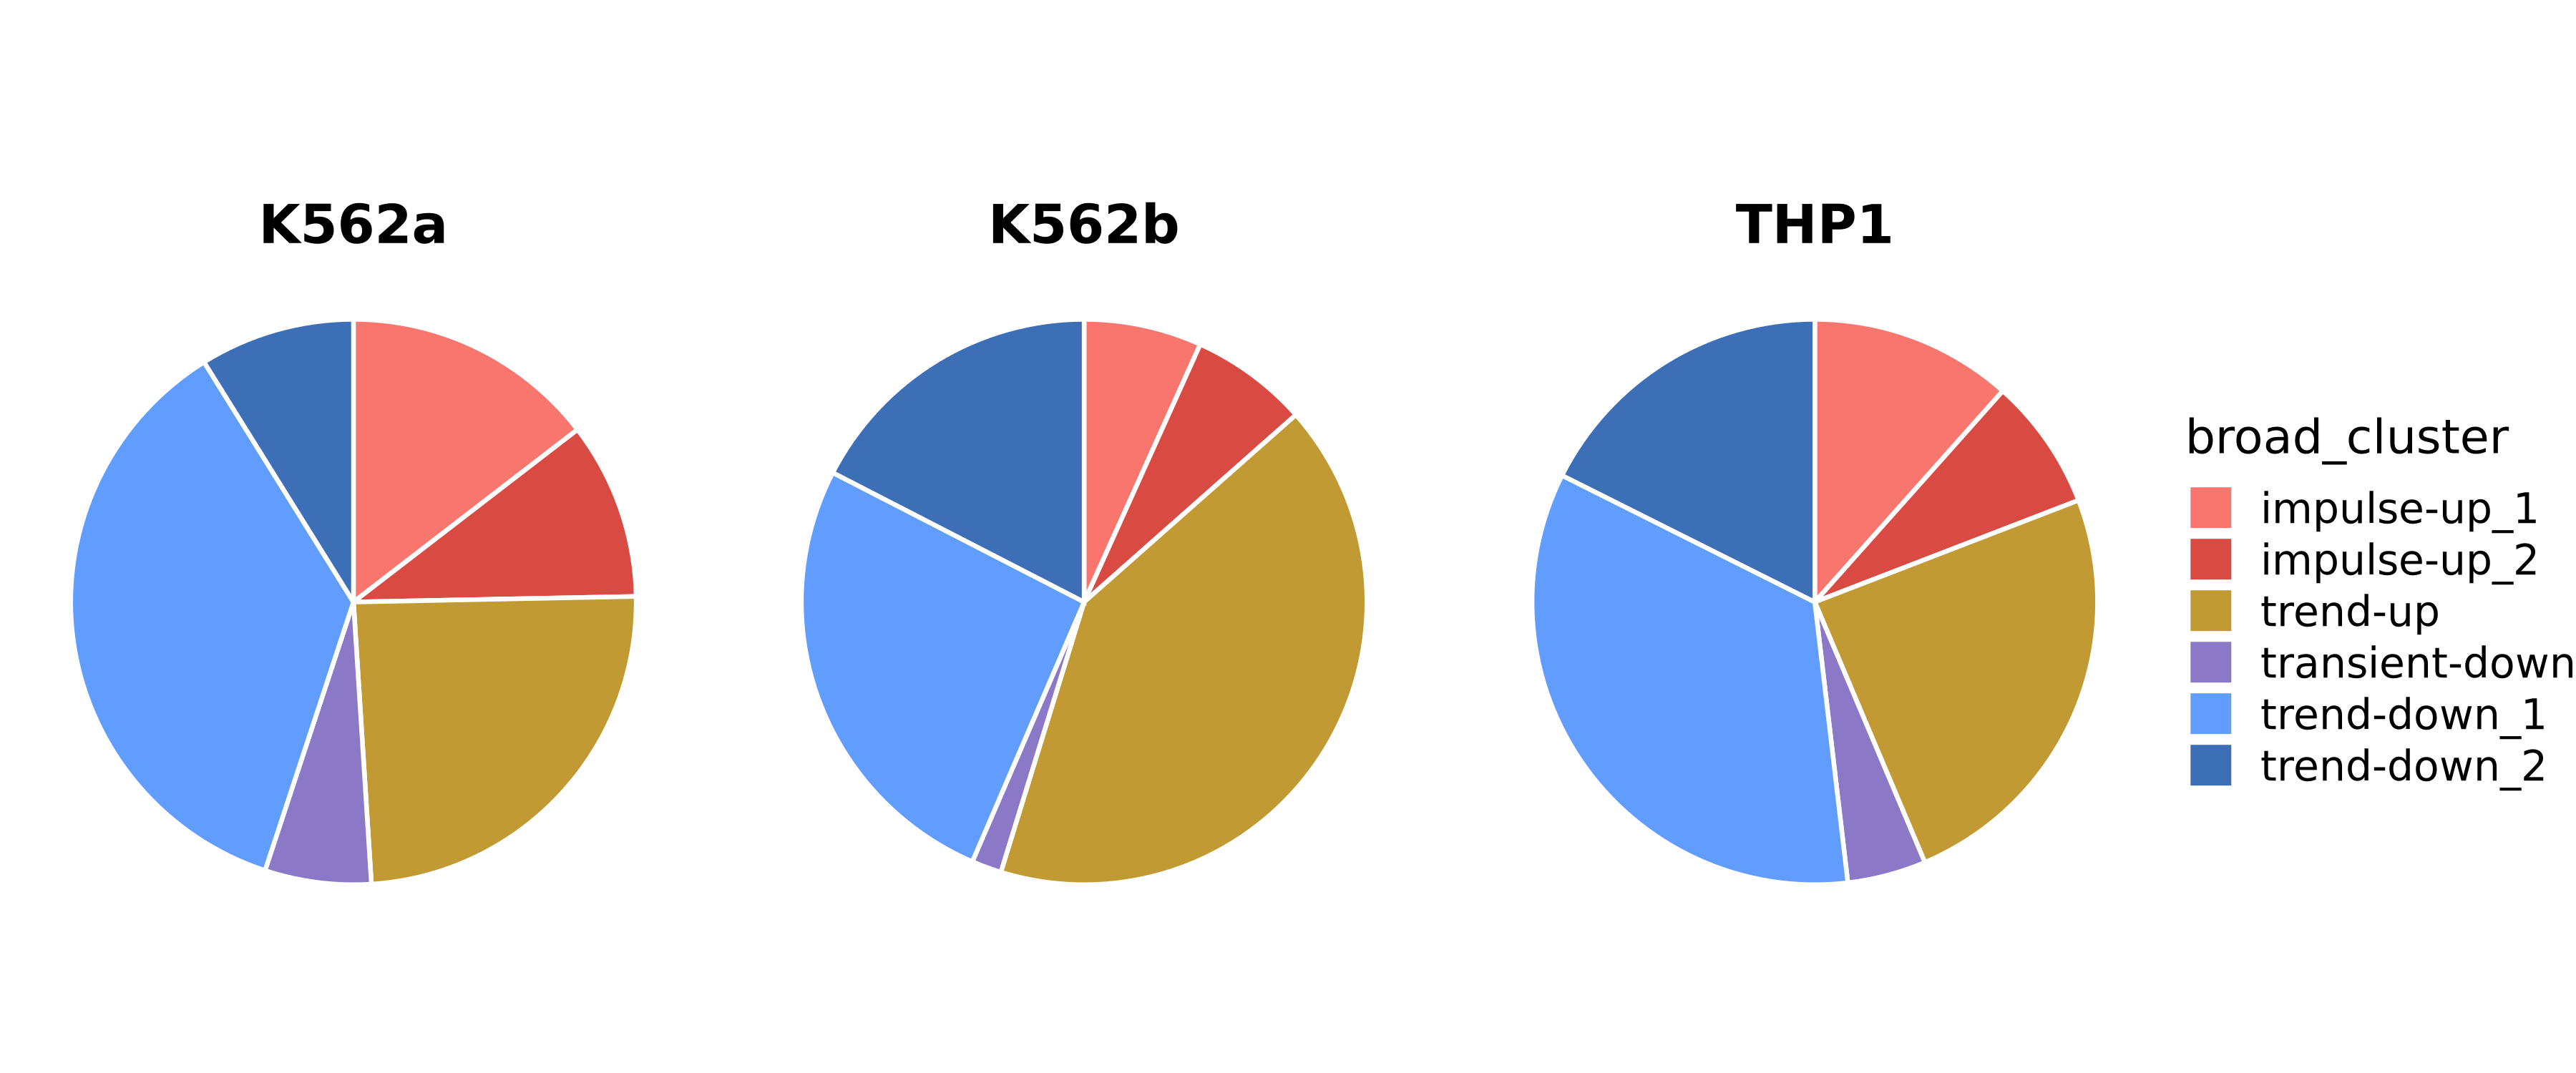

cell_type,K562a,K562b,THP1
broad_cluster,,,
impulse-up_1,0.146,0.067,0.116
impulse-up_2,0.101,0.067,0.076
transient-down,0.061,0.017,0.045
trend-down_1,0.361,0.261,0.343
trend-down_2,0.089,0.174,0.176
trend-up,0.243,0.413,0.245


In [5]:
responsive = adata[(adata.obs["peak_log2fc"].abs() >= 0.5) & (adata.obs["pvalue_1"] < 0.05)].copy()

proportions = cp.pl.mode_proportions(responsive, output=PLOT_DIR / "mode_proportions.svg")
display(proportions)
proportions.data.pivot(index="broad_cluster", columns="cell_type", values="prop").round(3)

## Mode reassignment between contexts

For each pair of contexts, the top 100 genes by Wald statistic in either context and their broad mode in both (flows of at least 2 genes). Genes without a significant mode in the other context are `low_significance`.

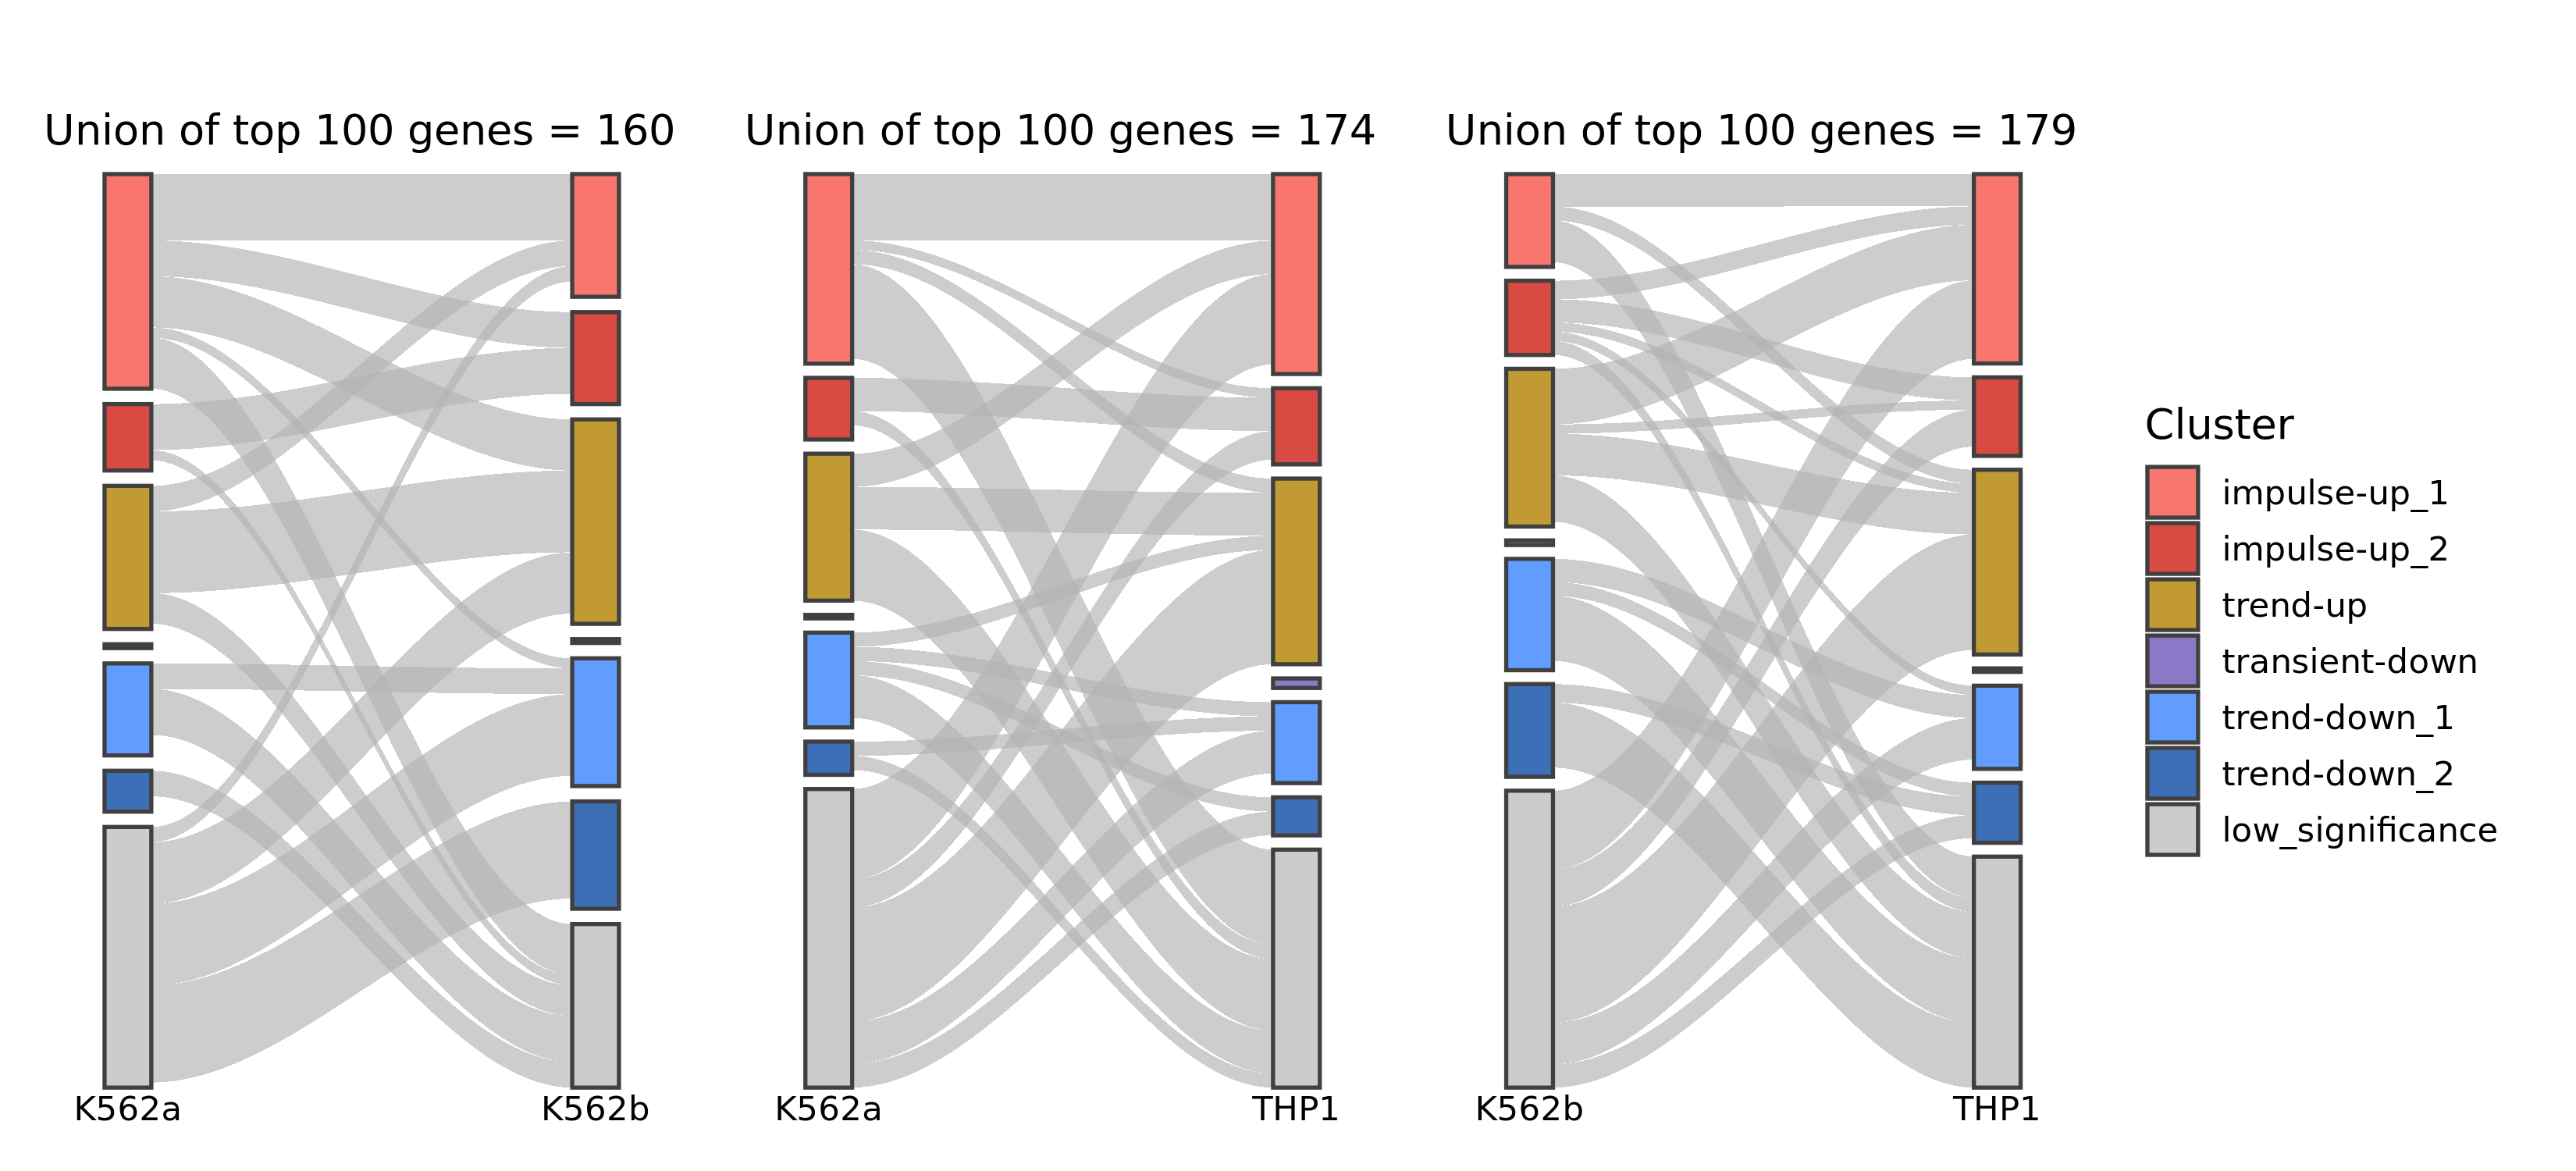

In [6]:
cp.pl.mode_sankey(
    responsive,
    pairs=[("K562a", "K562b"), ("K562a", "THP1"), ("K562b", "THP1")],
    top_k=100,
    output=PLOT_DIR / "mode_reassignment_sankeys.svg",
)

## Top-k mode recovery

Fraction of the 100 top source genes (by Wald statistic, q < 0.05) of a response direction (induced: impulse-up / trend-up modes; repressed: trend-down / transient-down) that have the same direction, with q < 0.05, in the target context.

In [7]:
cp.tl.topk_mode_recovery(
    responsive,
    pairs=[("K562a", "K562b"), ("K562a", "THP1"), ("THP1", "K562b")],
    modes=["induced", "repressed"],
    k=100,
)

,mode,source,target,k,recovery
0,induced,K562a,K562b,100,0.61
1,induced,K562a,THP1,100,0.35
2,induced,THP1,K562b,100,0.26
3,repressed,K562a,K562b,100,0.11
4,repressed,K562a,THP1,100,0.06
5,repressed,THP1,K562b,100,0.09


## Pairwise chord diagram

Mode reassignment among all three contexts: the union of each context's top 100 genes, links of at least 3 genes between modes of different contexts. Low-significance assignments are summarised as grey bars.

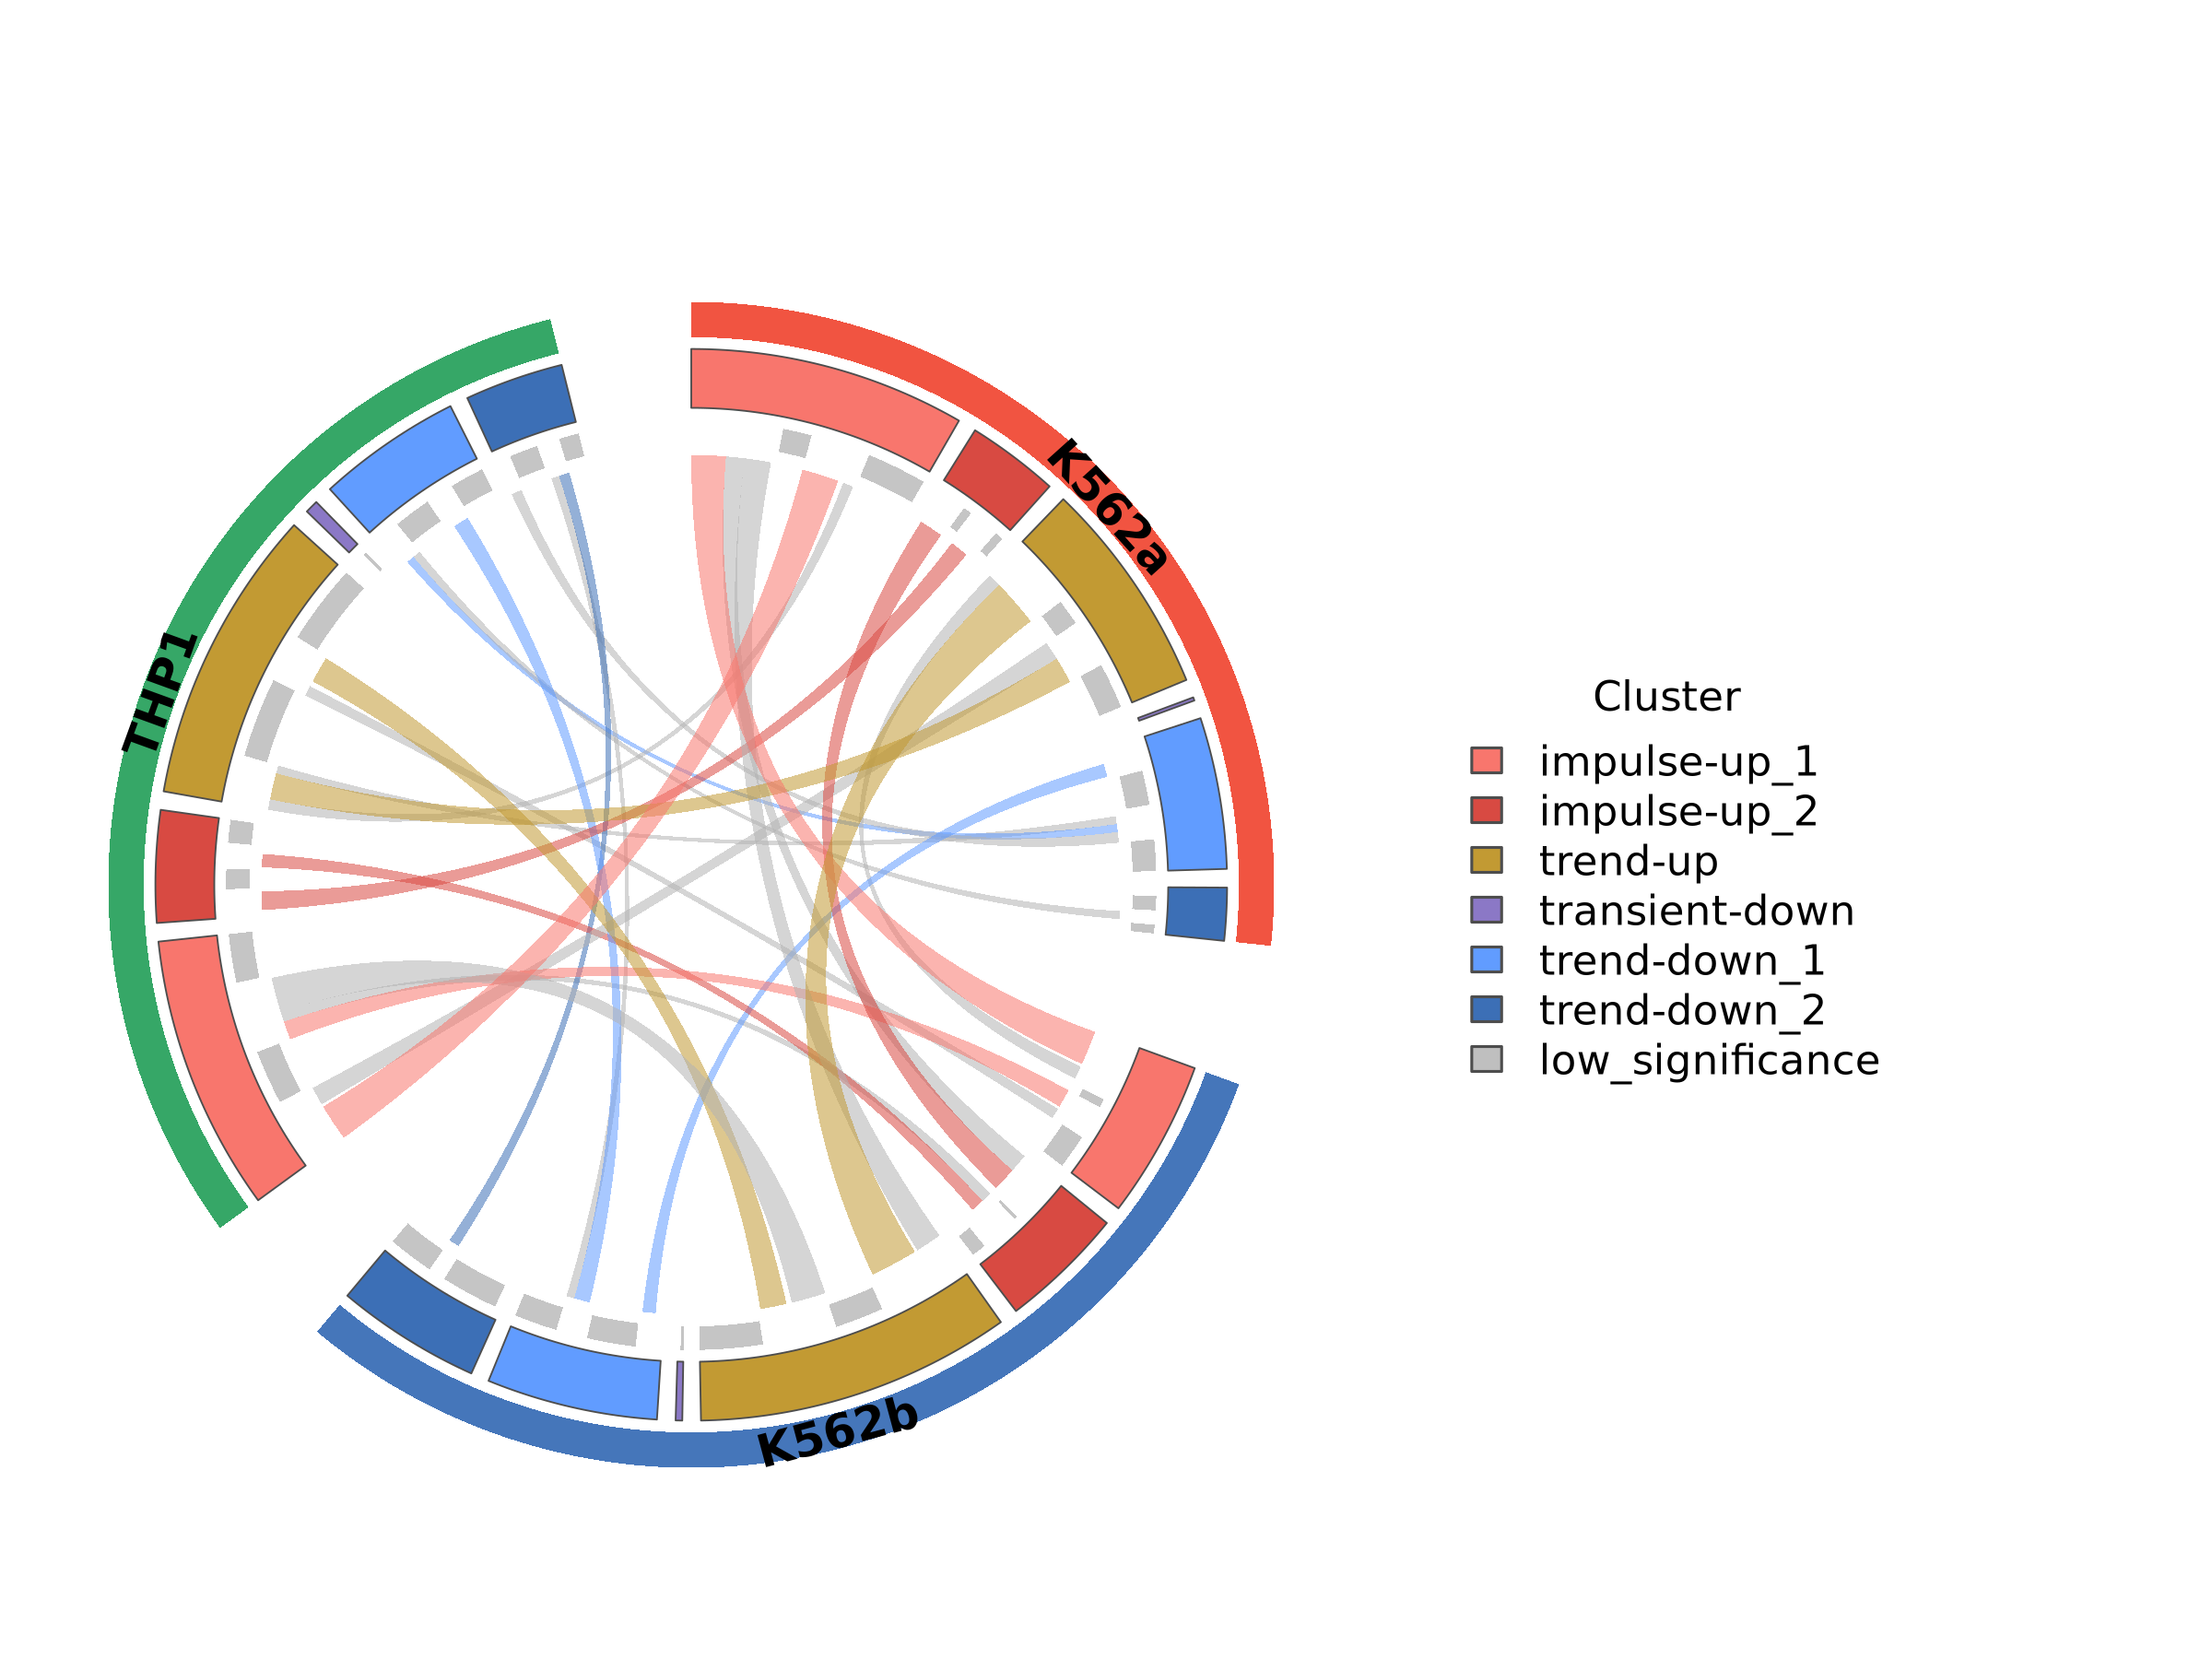

In [8]:
cp.pl.mode_chord(
    responsive,
    contexts=["K562a", "K562b", "THP1"],
    context_colors={"K562b": "#3b6fb6", "K562a": "#f04b37", "THP1": "#2ca25f"},
    top_k=100,
    min_flow=3,
    output=PLOT_DIR / "mode_reassignment_chord.svg",
)

## Representative genes per mode pair

Rows: broad mode in K562 + TNF-alpha; columns: broad mode in THP-1 + LPS. Each panel shows the gene with the highest K562a Wald statistic among genes in that pair of modes, as fitted tradeSeq curves of both contexts (blue K562a, black THP1). Genes in `exclude_genes` are used only when no other gene is available.

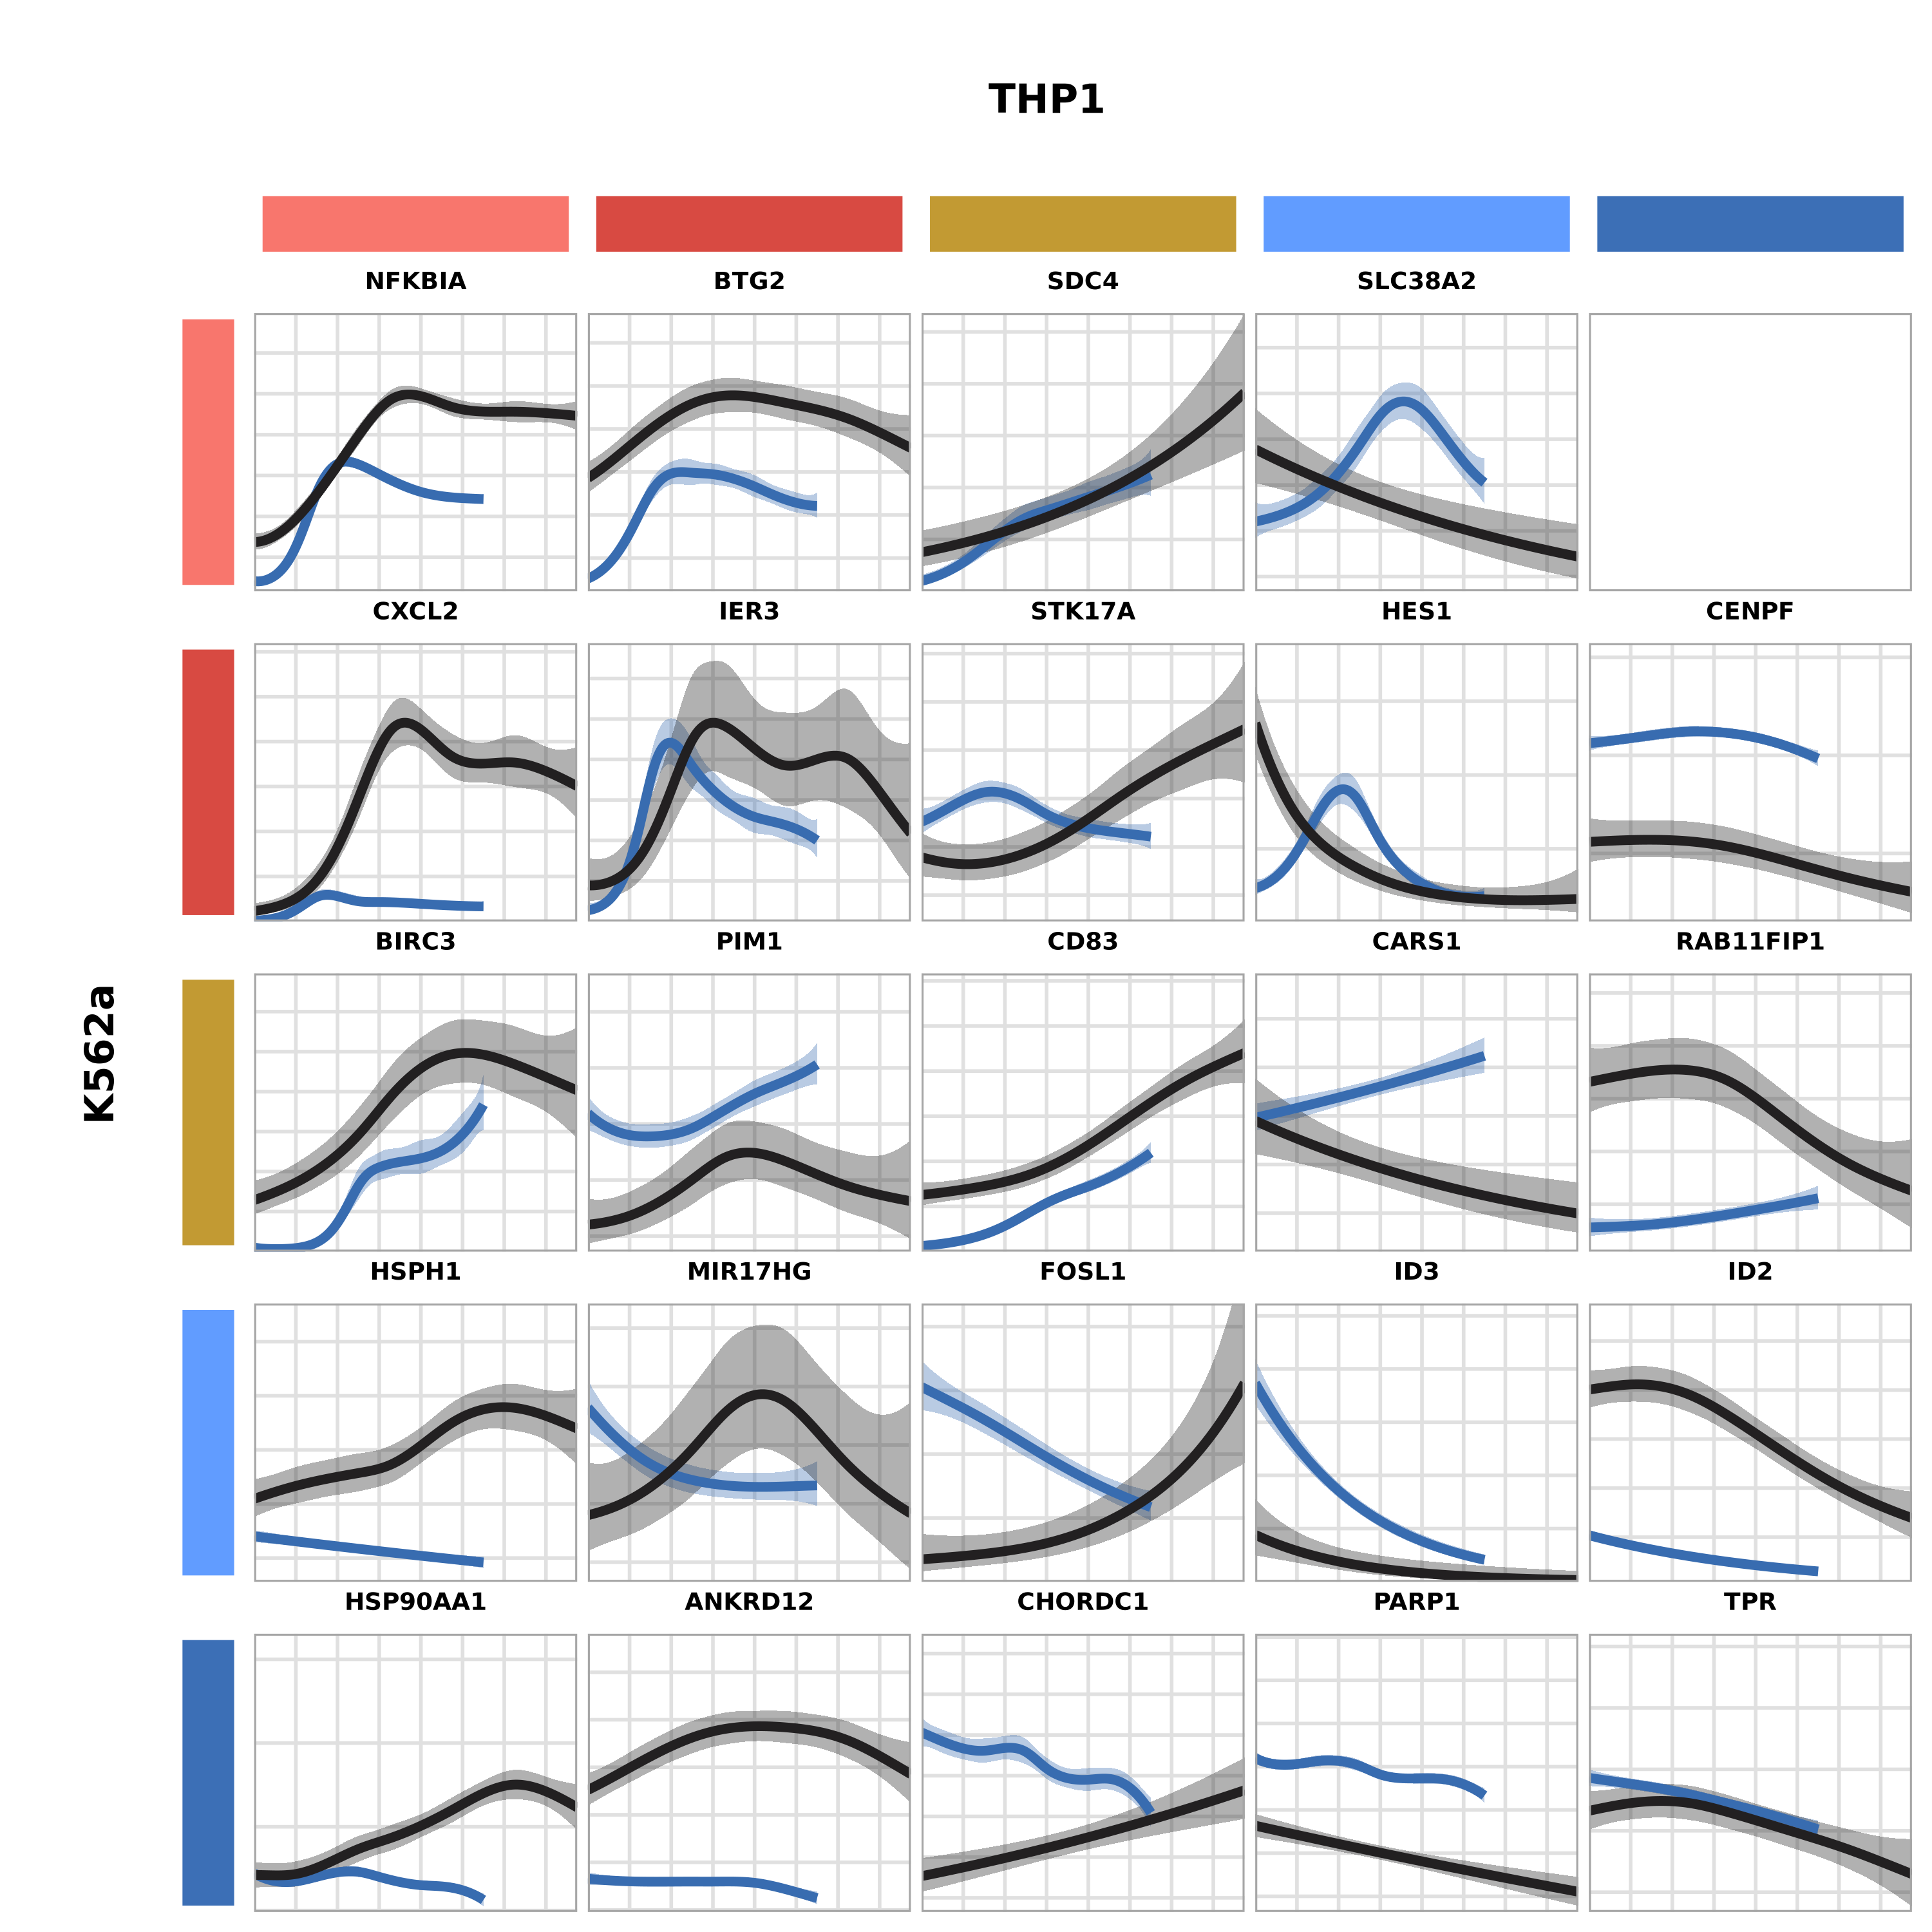

,row_cluster,col_cluster,gene,n_candidates_qpass
0,impulse-up_1,impulse-up_1,NFKBIA,19
1,impulse-up_1,impulse-up_2,BTG2,7
2,impulse-up_1,trend-up,SDC4,9
3,impulse-up_1,trend-down_1,SLC38A2,7
4,impulse-up_1,trend-down_2,NA_character_,0
5,impulse-up_2,impulse-up_1,CXCL2,2
6,impulse-up_2,impulse-up_2,IER3,11
7,impulse-up_2,trend-up,STK17A,5
8,impulse-up_2,trend-down_1,HES1,15
9,impulse-up_2,trend-down_2,CENPF,9


In [9]:
sce_dict = {
    "K562a": DATA_DIR / "k562-tnfa.hg38.rep" / "intmd" / "sc-K562-1e4_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
    "THP1": DATA_DIR / "thp1-k562-lps.hg38.rep" / "intmd" / "sc-THP1_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
}
pair_genes = cp.pl.cluster_pair_representative_genes(
    adata,
    sce_dict,
    row_context="K562a",
    col_context="THP1",
    clusters=["impulse-up_1", "impulse-up_2", "trend-up", "trend-down_1", "trend-down_2"],
    colours={"THP1": "#222021", "K562a": "#386cb0"},
    exclude_genes=["LAMTOR2", "SEPTIN9", "AP1S1", "CORO1C", "CTSZ", "LBR", "ZFP69B", "TM9SF2", "CKS1B"],
    output=PLOT_DIR / "cluster_pair_representative_genes.svg",
)
display(pair_genes)
pair_genes.data[["row_cluster", "col_cluster", "gene", "n_candidates_qpass"]]

## Peak and onset times of impulse-up genes

Peak and onset times of the top 100 impulse-up genes (impulse-up_1 and impulse-up_2 together) of each context.

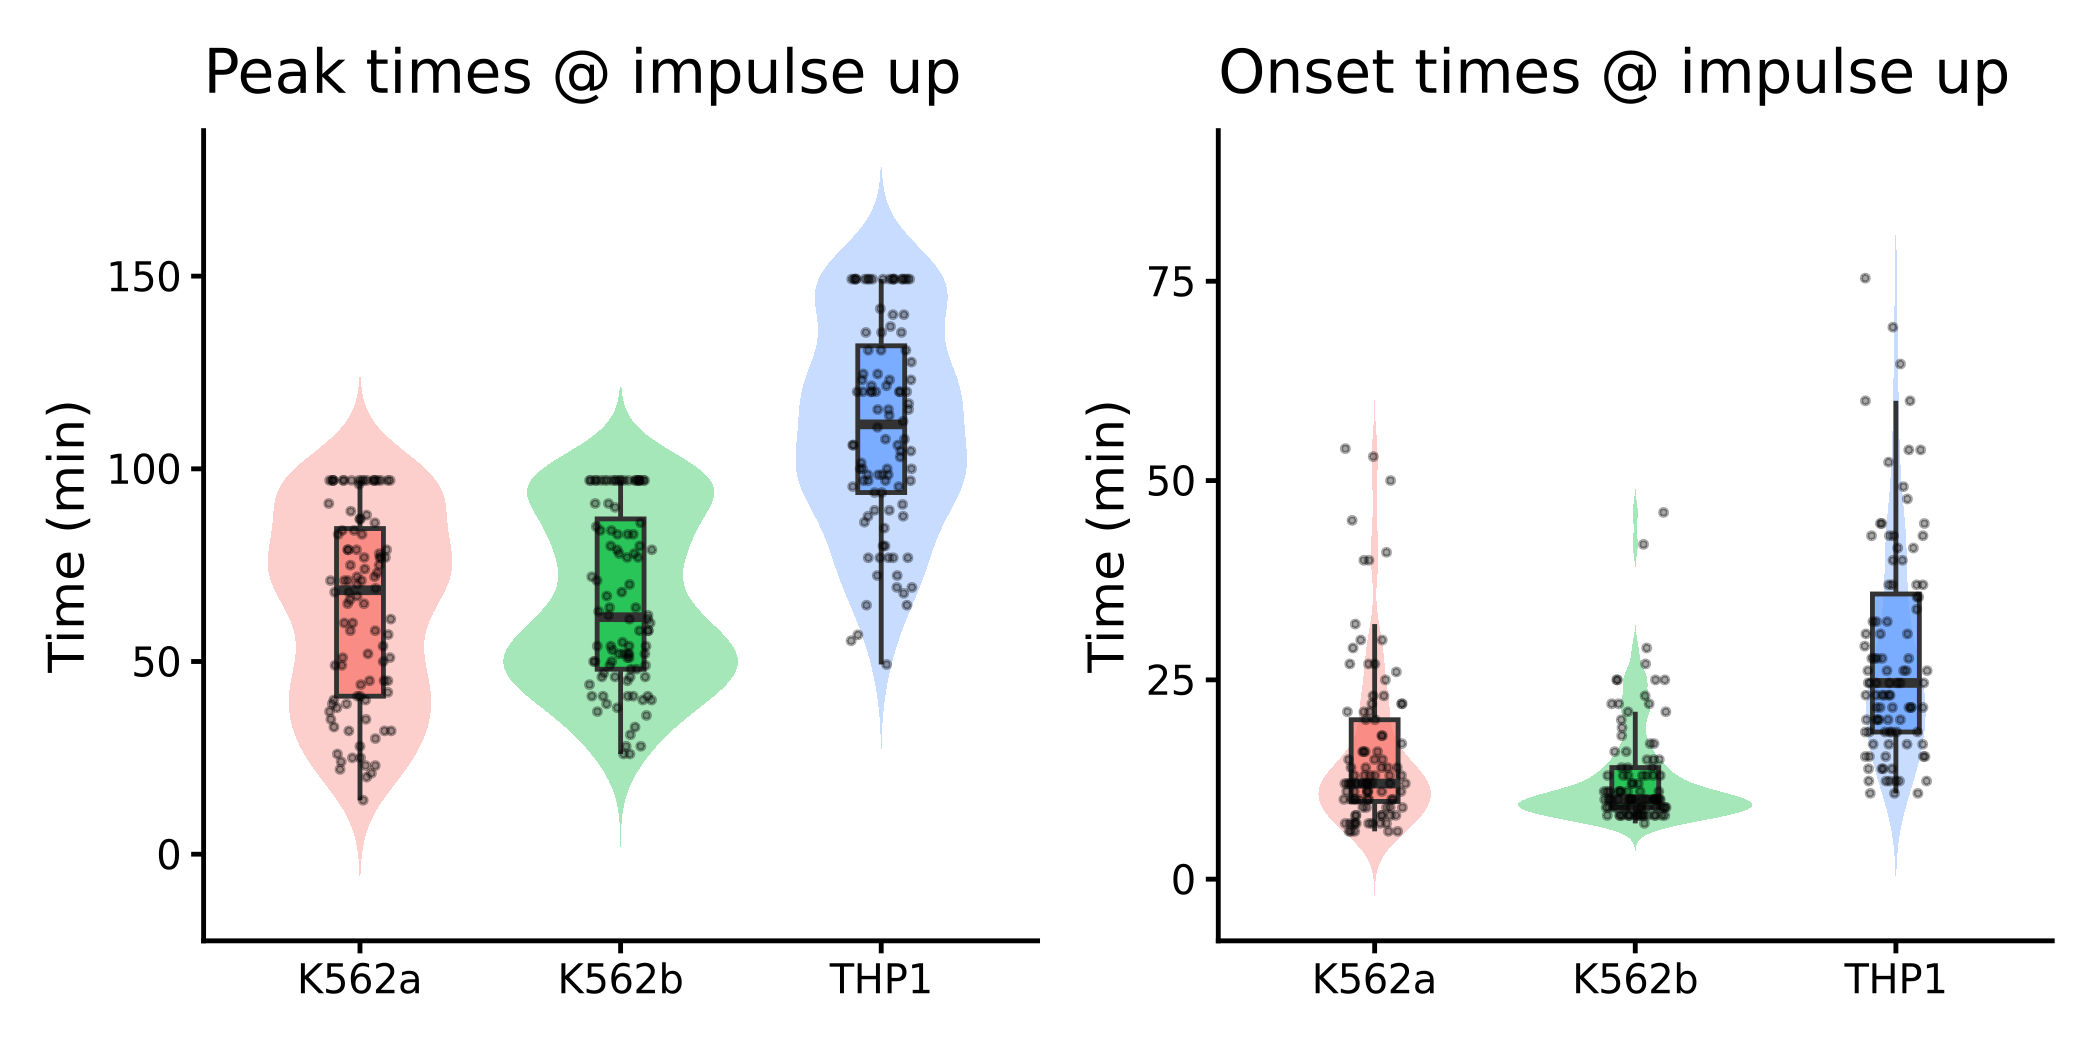

In [10]:
responsive.obs["broad_cluster2"] = responsive.obs["broad_cluster"].astype(str).replace(
    {"impulse-up_1": "impulse-up", "impulse-up_2": "impulse-up", "trend-down_1": "trend-down", "trend-down_2": "trend-down"}
)
cp.pl.cluster_violin(
    responsive,
    ["t_peak", "t_onset"],
    plot_titles=["Peak times @ impulse up", "Onset times @ impulse up"],
    y_title="Time (min)",
    cluster_col="broad_cluster2",
    cluster_use="impulse-up",
    contexts=["K562a", "K562b", "THP1"],
    top_k=100,
    output=PLOT_DIR / "impulse_up_peak_onset_times.svg",
)